# Combined case card

**Why this notebook.** `attribute_explainability` and `saliency_explainability` each end in a case
card for *their* arm, picked by *their* C2. The final system is the ensemble of the two arms, so one
call should be explained by both at once: what changes towards its counterfactual (attribute arm),
where C0's evidence sits (saliency arm), and where each arm's C2 puts it among C0's errors.

**How.** The two notebooks are not copied or merged. Each one runs here in a namespace of its own
(`ATTR`, `SAL`), up to its case-card cell, with figures and tables suppressed. Their panel functions
keep their own data, so `ATTR["error_map"]` draws the attribute map and `SAL["error_map"]` the CNN
map. Changes to a panel in either notebook show up here on the next run. A few settings are pinned
so the arms match: the disease, the CF source, K, coverage, and the two models of the ensemble.

**One X-ray, one verdict.** The two notebooks are joined on `path`, over the fold-4 queries both
cluster. The card's verdict (accept / defer) comes from the ensemble that combines exactly these two
models (`cf_<K>/ensemble/oof_predictions.csv`); the trust meter also shows each arm's own C2 and MSP.

**Choosing a case.** `pick_combined` filters on C0's call and outcome, the ensemble's verdict, MSP
agreeing or not, both arms agreeing with the verdict, and the group in each arm's embedding. It
prints how many X-rays survive each filter, so an empty combination says which filter emptied it.

In [1]:
import os, sys, io, re, json, time, warnings, contextlib, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

sys.path.insert(0, os.path.abspath("code"))

# effusion | atelectasis | cardiomegaly | consolidation | edema. XAI_DISEASE overrides it, as in the
# two source notebooks.
DISEASE    = os.environ.get("XAI_DISEASE", "cardiomegaly")
SOURCE     = "knn_correct_cf"
CF_K       = 10            # both arms and their ensemble, at K = 10
COVERAGE   = 0.80          # ONE global coverage: C2 keeps this share of all calls in a fold
ENS_METHOD = None          # None = the best combiner in ensemble_summary.csv; or "lr" | "rank" | "mean"
SHOW_LOGS  = False         # print everything the two source notebooks printed while loading
print(DISEASE, SOURCE, CF_K)

RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")
ENS_DIR = os.path.join(C2, DISEASE, SOURCE, f"cf_{CF_K}", "ensemble")

import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

# The cards go next to the single-arm ones (figures/xai/<disease>), with "combined" in the name.
SAVE_FIGS   = True
FIG_DIR     = os.path.join("figures", "xai", DISEASE)
FIG_FORMATS = ("pdf", "png")

def fig_path(name, ext):
    return os.path.join(FIG_DIR, f"{DISEASE}_{SOURCE}_combined_{name}.{ext}")

def save(fig, name):
    """Write `fig` as FIG_DIR/<disease>_<source>_combined_<name>.{pdf,png}."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in FIG_FORMATS:
            fig.savefig(fig_path(name, ext))

def save_text(name, text):
    """Write a card's caption / details beside it, as .txt."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        with open(fig_path(name, "txt"), "w", encoding="utf-8") as f:
            f.write(text.rstrip() + "\n")

# The ensemble behind the verdict: one attribute MLP + one image CNN. Both notebooks are pinned to
# exactly these two models (below), so every score on the card belongs to the ensemble's members.
ens_cfg = json.load(open(os.path.join(ENS_DIR, "run_config.json")))
ens_sum = pd.read_csv(os.path.join(ENS_DIR, "ensemble_summary.csv"))
display(ens_sum.round(4))
ENS_METHOD  = ENS_METHOD or (ens_sum[ens_sum["kind"] == "ensemble"]
                             .sort_values("auc_mean", ascending=False).iloc[0]["method"])
ATTR_MODEL  = ens_cfg["attr_model"]                     # "MLP_I+C+D"
ATTR_CONFIG = ATTR_MODEL.removeprefix("MLP_")           # "I+C+D"
CNN_MODEL   = ens_cfg["cnn_model"]                      # "dual_sal"
assert ens_cfg["attr_cf_count"] == ens_cfg["cnn_cf_count"] == CF_K, ens_cfg
print(f"verdict: ens_{ENS_METHOD} of {ATTR_MODEL} + {CNN_MODEL} (K = {CF_K})")

cardiomegaly knn_correct_cf 10


,kind,members,method,auc_mean,auc_std,delta_vs_best
0,ensemble,MLP_I+C+D_prob + dual_sal_prob,lr,0.9206,0.0029,0.0018
1,ensemble,MLP_I+C+D_prob + dual_sal_prob,rank,0.9205,0.0028,0.0017
2,ensemble,MLP_I+C+D_prob + dual_sal_prob,mean,0.9205,0.0028,0.0016
3,component,MLP_I+C+D_prob,-,0.9188,0.0031,NaN
4,component,dual_sal_prob,-,0.9163,0.0026,NaN


verdict: ens_lr of MLP_I+C+D + dual_sal (K = 10)


## 1. Load both arms

*Slow* (several minutes): this runs both notebooks' analysis cells, including the attribute
notebook's fold loading, both t-SNE maps and the saliency notebook's fold-4 Grad-CAMs. The
optional comparisons are switched off (`STUDY_SPACES`, `RUN_ALL_SPACES`), and so is figure saving.
The group-profile CSVs for TABLES.ipynb are still rewritten, with the same content.

In [2]:
# ── Run each source notebook in its own namespace ──
# Both notebooks use the same global names (data, cluster, TSNE_MAP, case_card...) for different
# things, so each runs in a dict of its own; functions defined there keep that dict as their
# globals. Every code cell runs, up to the first case-card example cell, with figures and tables
# suppressed. Pinned settings: their one-line top-level assignments are rewritten before the cell
# runs ("COVERAGE = 0.80  # ..." -> "COVERAGE = 0.8"), so the notebooks themselves stay untouched.
STOP_AT = "# A reliable case"            # first cell NOT run: the single-arm case-card examples

def pin_source(src, pins, log):
    out = []
    for line in src.split("\n"):
        m = re.match(r"([A-Za-z_]\w*)\s*=(?!=)", line)          # top level only (no indent)
        if m and m.group(1) in pins:
            new = f"{m.group(1)} = {pins[m.group(1)]!r}"
            log.append(f"{line.strip()[:70]}  ->  {new}")
            line = new
        out.append(line)
    return "\n".join(out)

@contextlib.contextmanager
def quiet():
    """No figures, no tables, stdout to a buffer (yielded) while a source cell runs."""
    show, buf = plt.show, io.StringIO()
    plt.show = lambda *a, **k: plt.close("all")
    try:
        with contextlib.redirect_stdout(buf), warnings.catch_warnings():
            warnings.simplefilter("ignore")
            yield buf
    finally:
        plt.show = show
        plt.close("all")

def load_notebook(nb_file, pins):
    """Run nb_file's code cells (up to STOP_AT) in a fresh namespace and return it."""
    cells = [c for c in json.load(open(nb_file))["cells"] if c["cell_type"] == "code"]
    ns    = {"__name__": f"xai_{nb_file.split('.')[0]}", "display": lambda *a, **k: None}
    pinned, out, t0 = [], [], time.time()
    for i, c in enumerate(cells):
        src = "".join(c["source"])
        if src.lstrip().startswith(STOP_AT):
            break
        with quiet() as buf:
            try:
                exec(compile(pin_source(src, pins, pinned), f"<{nb_file}: code cell {i}>", "exec"), ns)
            except Exception:
                print(buf.getvalue()[-3000:], file=sys.__stdout__)
                raise
        out.append(buf.getvalue())
    else:
        raise RuntimeError(f"{nb_file}: no cell starts with {STOP_AT!r}")
    unused = set(pins) - {p.split("->")[1].split("=")[0].strip() for p in pinned}
    assert not unused, f"{nb_file}: pins that match no assignment: {unused}"
    ns["_log"] = "\n".join(out)
    print(f"{nb_file}: {i} code cells in {(time.time() - t0) / 60:.1f} min; pinned:")
    print("   " + "\n   ".join(dict.fromkeys(pinned)))
    if SHOW_LOGS:
        print(ns["_log"])
    return ns

# k-means groups in BOTH arms (the source notebooks use 3). Any other number writes everything to
# figures/xai/<disease>/k<N>/: the source notebooks rewrite their group-profile CSVs on every run,
# even with SAVE_FIGS off, and TABLES.ipynb reads the 3-group ones from figures/xai/<disease>/.
N_GROUPS = 3
if N_GROUPS != 3:
    FIG_DIR = os.path.join("figures", "xai", DISEASE, f"k{N_GROUPS}")    # this notebook's cards too

COMMON = dict(DISEASE=DISEASE, SOURCE=SOURCE, K_VALUES=[CF_K], SAVE_FIGS=False,
              COVERAGE=COVERAGE, SCORE_SCOPE="all", N_CLUSTERS=N_GROUPS, FIG_DIR=FIG_DIR)
ATTR = load_notebook("attribute_explainability.ipynb",
                     {**COMMON, "CONFIG": ATTR_CONFIG, "STUDY_SPACES": False})
SAL  = load_notebook("saliency_explainability.ipynb",
                     {**COMMON, "MODEL": CNN_MODEL, "RUN_ALL_SPACES": False})

assert ATTR["BEST_K"] == SAL["BEST_K"] == CF_K
assert ATTR["BEST_CONFIG"] == ATTR_CONFIG and SAL["BEST_MODEL"] == CNN_MODEL
assert ATTR["EMB_FOLD"] == SAL["EMB_FOLD"] and ATTR["N_CLUSTERS"] == SAL["N_CLUSTERS"]
EMB_FOLD, N_CLUSTERS = ATTR["EMB_FOLD"], ATTR["N_CLUSTERS"]


attribute_explainability.ipynb: 14 code cells in 4.0 min; pinned:
   DISEASE = os.environ.get("XAI_DISEASE", "effusion")  ->  DISEASE = 'cardiomegaly'
   SOURCE  = "knn_correct_cf"     # or "diffusion_hml_sub20k"  ->  SOURCE = 'knn_correct_cf'
   K_VALUES = [10]               # knn: [10] | diffusion: [1]  ->  K_VALUES = [10]
   SAVE_FIGS   = True  ->  SAVE_FIGS = False
   FIG_DIR     = os.path.join("figures", "xai", DISEASE)  ->  FIG_DIR = 'figures/xai/cardiomegaly'
   CONFIG   = "I+C+D"   # always the complete model: query, counterfactua  ->  CONFIG = 'I+C+D'
   N_CLUSTERS = 3  ->  N_CLUSTERS = 3
   STUDY_SPACES = False                             # run the four-spaces  ->  STUDY_SPACES = False
   SCORE_SCOPE = "all"    # trust ranks: "all" = every call of the image'  ->  SCORE_SCOPE = 'all'
   COVERAGE    = 0.80     # ONE global coverage for every card: C2 keeps   ->  COVERAGE = 0.8


fold-4 CAMs:   0%|          | 0/18256 [00:00<?, ?it/s]

saliency_explainability.ipynb: 15 code cells in 1.4 min; pinned:
   DISEASE  = os.environ.get("XAI_DISEASE", "cardiomegaly")  ->  DISEASE = 'cardiomegaly'
   SOURCE   = "knn_correct_cf"  ->  SOURCE = 'knn_correct_cf'
   K_VALUES = [10]             # the embeddings are written per K by c2_e  ->  K_VALUES = [10]
   SAVE_FIGS   = True  ->  SAVE_FIGS = False
   RUN_ALL_SPACES = True   # step 6b: also cluster + t-SNE the embeddings  ->  RUN_ALL_SPACES = False
   FIG_DIR     = os.path.join("figures", "xai", DISEASE)  ->  FIG_DIR = 'figures/xai/cardiomegaly'
   MODEL   = None                   # None = best by AUROC; or a key such  ->  MODEL = 'dual_sal'
   N_CLUSTERS = 3  ->  N_CLUSTERS = 3
   SCORE_SCOPE = "all"    # trust ranks: "all" = every call of the image'  ->  SCORE_SCOPE = 'all'
   COVERAGE    = 0.80     # ONE global coverage for every card: C2 keeps   ->  COVERAGE = 0.8


## 2. One table, one row per X-ray in both arms

Every fold-4 query that both arms cluster, joined on `path`: its group letter and held-out flag in
each arm's embedding, each arm's C2 rank, the ensemble's rank and MSP's rank. All ranks are
percentiles within the X-ray's fold over all calls (0 = least, 1 = most trusted), so the deferral
cut at `COVERAGE` is the real one. The join checks that both arms see the same call: same C0
probability and outcome, same nearest counterfactual, and the ensemble's member scores equal to the
scores each arm read.

In [3]:
LETTERS = "ABCDEFGHIJ"

def arm_table(ns, arm):
    """One row per X-ray this arm clusters (fold 4, both sides of C0's call), indexed by path."""
    d, cl = ns["data"], ns["cluster"]
    assert d.index.equals(pd.RangeIndex(len(d))), f"{arm}: data index is not 0..n-1"
    k    = pd.concat([cl[1], cl[0]])                      # group id per row (1 = most errors)
    rows = k.index.values
    return pd.DataFrame({
        "path": d.loc[rows, "path"].values, "row": rows, "side": ns["pred"].loc[rows].values,
        "group": [LETTERS[N_CLUSTERS - g] for g in k.values],
        "held_out": ns["held_out"].loc[rows].values, "outcome": ns["quadrant"][rows],
        "correct": d.loc[rows, "correct"].astype(int).values, "fold": d.loc[rows, "fold"].values,
        "prob": d.loc[rows, f"{DISEASE}_prob"].values, "cf_path": d.loc[rows, "cf_path"].values,
        "cf_prob": d.loc[rows, "cf_prob"].values, "score": d.loc[rows, "model_score"].values,
        "rank": d.loc[rows, "c2_rank"].values, "msp_rank": d.loc[rows, "msp_rank"].values,
    }).set_index("path")

ta, ti = arm_table(ATTR, "attribute"), arm_table(SAL, "image")
J = ta.join(ti, how="inner", lsuffix="_attr", rsuffix="_img")
print(f"fold {EMB_FOLD}: {len(ta):,} X-rays in the attribute arm, {len(ti):,} in the image arm, "
      f"{len(J):,} in both")

# Both arms must describe the same call of the same X-ray, with the same counterfactual.
for col in ["side", "outcome", "correct", "fold", "cf_path"]:
    bad = (J[f"{col}_attr"] != J[f"{col}_img"]).sum()
    assert bad == 0, f"{bad:,} X-rays differ in {col} between the arms"
for col, tol in [("prob", 1e-4), ("cf_prob", 1e-4), ("msp_rank", 0.01)]:
    gap = (J[f"{col}_attr"] - J[f"{col}_img"]).abs().max()
    assert gap <= tol, f"{col} differs between the arms by up to {gap:.4f}"

# The ensemble's verdict: its out-of-fold score, ranked like the arms' C2 scores (per fold, all calls).
oof = pd.read_csv(os.path.join(ENS_DIR, "oof_predictions.csv")).set_index("path")
oof["ens_rank"] = oof.groupby("fold")[f"ens_{ENS_METHOD}"].rank(pct=True)
assert J.index.isin(oof.index).all(), "some X-rays have no ensemble score"
o = oof.loc[J.index]
assert (o["fold"].values == J["fold_attr"].values).all(), "the ensemble puts X-rays in other folds"
for arm, col in [("attr", f"{ATTR_MODEL}_prob"), ("img", f"{CNN_MODEL}_prob")]:
    gap = (J[f"score_{arm}"] - o[col]).abs().max()
    assert gap < 1e-4, f"the ensemble's {col} differs from the {arm} arm's C2 score by {gap:.2g}"

keep = {"side_attr": "side", "outcome_attr": "outcome", "correct_attr": "correct",
        "prob_attr": "prob", "cf_path_attr": "cf_path", "cf_prob_attr": "cf_prob",
        "msp_rank_attr": "msp_rank", "row_attr": "row_attr", "row_img": "row_img",
        "group_attr": "group_attr", "group_img": "group_img",
        "held_out_attr": "held_out_attr", "held_out_img": "held_out_img",
        "rank_attr": "rank_attr", "rank_img": "rank_img"}
J = J[list(keep)].rename(columns=keep).assign(ens_rank=o["ens_rank"].values)
SIDE_NAME = ATTR["SIDE_NAME"]
display(J.head().round(3))

fold 4: 18,256 X-rays in the attribute arm, 18,256 in the image arm, 18,256 in both


,side,outcome,correct,prob,cf_path,cf_prob,msp_rank,row_attr,row_img,group_attr,group_img,held_out_attr,held_out_img,rank_attr,rank_img,ens_rank
path,,,,,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient00045/study1/view1_frontal.jpg,1,FP,0,0.591,CheXpert-v1.0-small/train/patient06745/study1/...,0.071,0.194,74260,74260,C,B,False,False,0.139,0.167,0.148
CheXpert-v1.0-small/train/patient00047/study1/view1_frontal.jpg,1,TP,1,0.757,CheXpert-v1.0-small/train/patient44322/study3/...,0.132,0.230,74261,74261,A,A,True,True,0.262,0.242,0.254
CheXpert-v1.0-small/train/patient00047/study2/view1_frontal.jpg,1,TP,1,0.564,CheXpert-v1.0-small/train/patient32550/study1/...,0.027,0.188,74262,74262,A,A,True,True,0.240,0.226,0.237
CheXpert-v1.0-small/train/patient00047/study4/view1_frontal.jpg,1,TP,1,0.673,CheXpert-v1.0-small/train/patient40443/study7/...,0.018,0.212,74264,74264,A,A,True,True,0.251,0.223,0.244
CheXpert-v1.0-small/train/patient00047/study5/view1_frontal.jpg,1,FP,0,0.789,CheXpert-v1.0-small/train/patient45039/study1/...,0.010,0.235,74265,74265,A,A,True,True,0.273,0.250,0.264


### What exists

Fold-4 X-rays not seen by k-means in either arm, counted by C0's call and outcome, the ensemble's
verdict, whether MSP alone reaches the same verdict, and whether both arms' C2 do. `pick_combined`
also keeps a `margin` from the cut (default 0.05), so these counts are upper bounds: where C2 and
MSP disagree, both usually sit just around the cut, and only a small margin (0.01) keeps them. Below: how the two arms'
groups line up (rows = attribute group, columns = image group).

In [4]:
thr  = 1 - COVERAGE
ho   = J[J["held_out_attr"] & J["held_out_img"]]
verd = lambda r: np.where(r >= thr, "accept", "defer")
v    = verd(ho["ens_rank"])
grid = pd.DataFrame({
    "call": ho["side"].map(SIDE_NAME), "outcome": ho["outcome"], "C2": v,
    "MSP": np.where(verd(ho["msp_rank"]) == v, "agrees", "disagrees"),
    "arms": np.where((verd(ho["rank_attr"]) == v) & (verd(ho["rank_img"]) == v), "both agree", "split")})
print(f"{len(ho):,} X-rays held out in both arms; at {COVERAGE:.0%} coverage")
display(grid.groupby(["call", "outcome", "C2", "MSP", "arms"]).size()
            .unstack(["MSP", "arms"], fill_value=0))

for p in SIDE_NAME:
    s = J[J["side"] == p]
    print(f"\n{SIDE_NAME[p]}: attribute group (rows) vs image group (columns), n and C0's error rate")
    display(pd.concat({"n": pd.crosstab(s["group_attr"], s["group_img"]),
                       "error rate": pd.crosstab(s["group_attr"], s["group_img"],
                                                 values=1 - s["correct"], aggfunc="mean").round(2)},
                      axis=1))

9,414 X-rays held out in both arms; at 80% coverage


MSP                               agrees        disagrees      
arms                          both agree split both agree split
call           outcome C2                                      
Negative calls FN      accept        277     0          0     0
               TN      accept       6655     0          0     0
Positive calls FP      accept        107    38         24    34
                       defer        1236    56         48    20
               TP      accept        312    46         30    32
                       defer         395    47         29    28


Positive calls: attribute group (rows) vs image group (columns), n and C0's error rate


n            error rate            
group_img     A     B    C          A     B     C
group_attr                                       
A           946   289    9       0.31  0.56  0.78
B           305  1200  335       0.56  0.69  0.83
C            95   997  624       0.63  0.76  0.84


Negative calls: attribute group (rows) vs image group (columns), n and C0's error rate


n             error rate            
group_img      A     B     C          A     B     C
group_attr                                         
A           1850  1119   141       0.01  0.01  0.02
B           1591  3151  1280       0.02  0.02  0.05
C            172  1306  2846       0.03  0.05  0.11

## 3. Choosing the X-ray

`pick_combined(side, ...)` returns the path of a fold-4 X-ray that passes every filter:

| argument | values | meaning |
|---|---|---|
| `side` | `1`, `0` | C0 said positive / negative |
| `outcome` | `"correct"`, `"wrong"`, `"TP"`, `"FP"`, `"TN"`, `"FN"`, `None` | how C0's call turned out |
| `verdict` | `"accept"`, `"defer"`, `None` | the ensemble C2 at `COVERAGE`, at least `margin` (default 0.05) from the cut |
| `msp` | `"agree"`, `"disagree"` (with `verdict`), `"accept"`, `"defer"`, `None` | where MSP alone puts it, also `margin` from the cut |
| `arms` | `"agree"`, `"split"`, `None` | both arms' C2 on the verdict's side of the cut / the two arms on opposite sides |
| `group_attr`, `group_img` | `"A"`, `"B"`, ... , `None` | its group in each arm's embedding (A = fewest errors) |
| `held_out` | `"both"`, `"any"`, `None` | not seen by k-means in both arms / in at least one |

As in the single-arm notebooks, the candidates are then ranked by how clearly they sit in their
group (distance to the nearest other group centre over the distance to their own), here the
*smaller* of the two arms' values, after dropping X-rays whose drawn profile (d's attributes, h's
regions) is far from their group's average in either arm. `nth` steps down that table.

In [5]:
def arm_fit(ns, rows, side, kind):
    """Per row of one arm: clearness (nearest other group centre / own centre, in the clustering
    space) and profile gap (mean |SD| distance of its drawn profile from its group's average), as
    that notebook's pick_case computes them."""
    X, centres = ns["group_geometry"](side)
    k     = ns["cluster"][side].loc[rows].values
    d     = np.linalg.norm(X.loc[rows].values[:, None, :] - centres.values[None], axis=2)
    own   = centres.index.get_indexer(k)
    dist  = d[np.arange(len(rows)), own]
    d[np.arange(len(rows)), own] = np.inf
    clear = d.min(axis=1) / dist
    gap   = np.empty(len(rows))
    for g in np.unique(k):
        sel  = k == g
        in_k = ns["cluster"][side].index[(ns["cluster"][side] == g).values]
        if kind == "attr":                               # image and CF on the card's attributes
            a, zq, zc = KEY_ATTRS(side), ns["zq"], ns["zc"]
            gap[sel] = ((zq.loc[rows[sel], a] - zq.loc[in_k, a].mean()).abs().mean(axis=1)
                        + (zc.loc[rows[sel], a] - zc.loc[in_k, a].mean()).abs().mean(axis=1)).values / 2
        else:                                            # support and against on the key regions
            a    = ns["profile_regions"](side)
            both = pd.concat([ns["ZS"][a].add_prefix("sup "), ns["ZO"][a].add_prefix("opp ")], axis=1)
            gap[sel] = (both.loc[rows[sel]] - both.loc[in_k].mean()).abs().mean(axis=1).values
    return clear, gap

def pick_combined(side, outcome=None, verdict=None, msp=None, arms=None, group_attr=None,
                  group_img=None, held_out="both", margin=0.05, n_show=5, nth=0):
    """Path of a fold-4 X-ray passing every filter (see the table above), clearest in both arms
    first; None (and the filter chain) when none does."""
    thr  = 1 - COVERAGE
    flip = {"accept": "defer", "defer": "accept"}
    on   = lambda r, cut, m: (r >= thr + m) if cut == "accept" else (r < thr - m)
    c, steps = J[J["side"] == side], []
    steps.append((f"{SIDE_NAME[side].lower()}, fold {EMB_FOLD}", len(c)))

    def keep(label, mask):
        nonlocal c
        c = c[np.asarray(mask)]
        steps.append((label, len(c)))

    if held_out == "both":
        keep("held out in both arms", c["held_out_attr"] & c["held_out_img"])
    elif held_out == "any":
        keep("held out in an arm", c["held_out_attr"] | c["held_out_img"])
    if outcome in ("correct", "wrong"):
        keep(f"C0 {outcome}", c["correct"] == (outcome == "correct"))
    elif outcome is not None:
        keep(outcome, c["outcome"] == outcome)
    if verdict is not None:
        keep(f"C2 {verdict}s", on(c["ens_rank"], verdict, margin))
    if msp in ("agree", "disagree"):
        assert verdict, "msp='agree' / 'disagree' needs a verdict"
        cut = verdict if msp == "agree" else flip[verdict]
        keep(f"MSP would {cut}", on(c["msp_rank"], cut, margin))
    elif msp is not None:
        keep(f"MSP would {msp}", on(c["msp_rank"], msp, margin))
    if arms == "agree":
        assert verdict, "arms='agree' needs a verdict"
        keep(f"both arms {verdict}", on(c["rank_attr"], verdict, 0) & on(c["rank_img"], verdict, 0))
    elif arms == "split":
        keep("arms split", (c["rank_attr"] >= thr) != (c["rank_img"] >= thr))
    if group_attr is not None:
        keep(f"attribute group {group_attr}", c["group_attr"] == group_attr)
    if group_img is not None:
        keep(f"image group {group_img}", c["group_img"] == group_img)

    print("  →  ".join(f"{label} {n:,}" for label, n in steps))
    if not len(c):                                       # None: combined_card draws nothing
        print("no X-ray passes every filter: relax the one that emptied the pool (above)")
        return None

    ca, ga = arm_fit(ATTR, pd.Index(c["row_attr"]), side, "attr")
    ci, gi = arm_fit(SAL,  pd.Index(c["row_img"]),  side, "img")
    score = c[["outcome", "group_attr", "group_img", "ens_rank", "rank_attr", "rank_img",
               "msp_rank"]].assign(clear_attr=ca, clear_img=ci, gap_attr=ga, gap_img=gi)
    score["clearness"] = np.minimum(ca, ci)
    typical = (score["gap_attr"] <= score["gap_attr"].median()) & (score["gap_img"] <= score["gap_img"].median())
    if typical.any():                                    # typical profile in both arms, if any is
        score = score[typical]
    score = score.sort_values("clearness", ascending=False)
    print(f"{len(score)} candidates with a typical profile in both arms")
    display(score.head(max(n_show, nth + 1)).round(3))
    return score.index[nth]

## 4. The card

Three rows, one per layer of the explanation, each marked on the left:

* **The call.** **a** the X-ray and C0's call, with the attribute group's organs outlined. **b** the
  trust meter: the ensemble C2 (its verdict), each arm's C2 and MSP, as ranks among all calls of the
  fold, with the deferral cut at `COVERAGE`. Then the key.
* **Attribute arm.** **c** the nearest counterfactual. **d** what changes from the X-ray to it, on
  the side's key attributes, the rows of the attribute notebook's `embedding_group_profiles` figure
  (upper: this X-ray, lower dashed: its group's average).
  **e** where it sits on the attribute C2's map of C0's errors. **f** how often C0 is wrong in that group.
* **Saliency arm.** **g** C0's Grad-CAM, green supporting the call, purple against it. **h** focus
  per key region, support (●) and against (✕), vs its image group's average (grey). **i**, **j** as
  e, f on the image C2's map.

The groups of e/f and i/j come from two different embeddings, so their letters need not match.

In [18]:
GLYPHS, OUTCOME, per100 = ATTR["GLYPHS"], ATTR["OUTCOME"], ATTR["per100"]
ACCEPT_C, DEFER_C       = ATTR["ACCEPT_C"], ATTR["DEFER_C"]
DB_EDGE, DB_HOLLOW      = ATTR["DB"]["edge"], ATTR["DB"]["hollow"]   # dumbbell dot edges, for the key

# ── Card grid (mm): 3 rows x 4 equal squares, arm bands in the left margin ──
CC_W     = FULL / MM                               # 183 mm
CC_L     = 9                                       # left margin: the arm bands and their names
CC_R     = 2                                       # right margin
CC_G     = 8                                       # gap between columns
CC_S     = (CC_W - CC_L - CC_R - 3 * CC_G) / 4     # side of one square panel (~37 mm)
CC_HD    = 2                                       # top margin (the caption goes to a .txt)
CC_T     = 10                                      # title + subtitle above each row's squares
CC_U     = (3, 10, 10)                             # under each row: x labels, the maps' colour bars
CC_SEP   = 4                                       # rule between rows
CC_BLOCK = [CC_T + CC_S + u + CC_SEP for u in CC_U]
CC_H     = CC_HD + sum(CC_BLOCK) - CC_SEP
TITLE_LINE, TITLE_WRAP = 3.2, 30                   # mm per title line (7.5 pt); characters per line
ARMS = [("The call", MUTED), ("Attribute arm", FAMILY["attr"]), ("Saliency arm", FAMILY["cnn"])]

def KEY_ATTRS(p):
    """Panel d's rows: the side's key attributes (attribute notebook, step 4), so every card of a
    side shows the same five (its embedding_group_profiles figure draws the top three)."""
    return ATTR["selected"][p]

def key_organs(p):
    """The segmented organs behind the side's key attributes, outlined on a and c."""
    return [t for t in ATTR["SEG_MODEL"].targets if any(t in a for a in KEY_ATTRS(p))]

def cc_top(r):
    """mm from the top of the figure to the top of row r's squares."""
    return CC_HD + sum(CC_BLOCK[:r]) + CC_T

def cc_cell(r, c, span=1):
    """[left, bottom, width, height] (figure fraction) of row r, column c, `span` columns wide."""
    x = CC_L + c * (CC_S + CC_G)
    w = span * CC_S + (span - 1) * CC_G
    return [x / CC_W, 1 - (cc_top(r) + CC_S) / CC_H, w / CC_W, CC_S / CC_H]

def cc_title(fig, r, c, letter, head, sub=""):
    """Panel letter + bold title, muted subtitle under it; every row's titles at one height."""
    x, y  = (CC_L + c * (CC_S + CC_G)) / CC_W, 1 - (cc_top(r) - CC_T + 0.5) / CC_H
    lines = textwrap.wrap(head, TITLE_WRAP)
    kw    = dict(fontsize=FS["title"], fontweight="bold", va="top", linespacing=1.15)
    fig.text(x, y, letter, **kw)
    fig.text(x + 3.4 / CC_W, y, "\n".join(lines), **kw)
    fig.text(x + 3.4 / CC_W, y - (len(lines) * TITLE_LINE + 0.6) / CC_H, sub,
             fontsize=FS["small"], color=MUTED, va="top", fontfamily=GLYPHS)

def arm_band(fig, r):
    """Row r's arm: a coloured bar and its name in the left margin, a hairline above the row."""
    name, color = ARMS[r]
    y0, y1 = 1 - (cc_top(r) + CC_S) / CC_H, 1 - (cc_top(r) - CC_T + 0.5) / CC_H
    fig.add_artist(plt.Line2D([2 / CC_W] * 2, [y0, y1], color=color, lw=2.2, solid_capstyle="butt"))
    fig.text(3.6 / CC_W, (y0 + y1) / 2, name, rotation=90, ha="left", va="center", color=color,
             fontsize=FS["head"], fontweight="bold")
    if r:
        y = 1 - (cc_top(r) - CC_T - CC_SEP / 2) / CC_H
        fig.add_artist(plt.Line2D([(CC_L - 1) / CC_W, 1 - CC_R / CC_W], [y, y], color=HAIR,
                                  lw=LW["hair"]))

def verdict_of(r):
    return "accept" if r >= 1 - COVERAGE else "defer"

def trust_panel(ax, j):
    """One bar from least to most trusted, the deferral cut dashed. Above it ▼ the ensemble C2 (the
    verdict) and each arm's C2; below it △ MSP; the verdict, and MSP's, under the bar."""
    thr = 1 - COVERAGE
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(0, 1); ax.axis("off")
    ax.imshow(np.linspace(0, 1, 256)[None], extent=[0, 1, 0.47, 0.57], aspect="auto",
              cmap="RdYlGn", zorder=1)
    ax.plot([thr, thr], [0.44, 0.60], color=INK, lw=LW["ref"], ls="--", zorder=2)
    ax.text(thr / 2, 0.52, "defer", ha="center", va="center", fontsize=FS["tiny"], color="white",
            fontweight="bold", zorder=2)
    ax.text((1 + thr) / 2, 0.52, "accept", ha="center", va="center", fontsize=FS["tiny"],
            color=INK, fontweight="bold", zorder=2)

    def mark(x, y, label, marker, face, edge, bold=False):
        ax.scatter([x], [y], marker=marker, s=40, facecolor=face, edgecolor=edge, lw=0.8, zorder=3)
        right = x > 0.6                                  # label on the inner side of the marker
        ax.text(x + (-0.04 if right else 0.04), y, label, ha="right" if right else "left",
                va="center", fontsize=FS["small"], color=INK, fontweight="bold" if bold else "normal",
                fontfamily=GLYPHS)
    mark(j["rank_img"],  0.88, f"image C2 · {j['rank_img']:.0%}",  "v", FAMILY["cnn"], "white")
    mark(j["rank_attr"], 0.77, f"attribute C2 · {j['rank_attr']:.0%}", "v", FAMILY["attr"], "white")
    mark(j["ens_rank"],  0.66, f"C2 · {j['ens_rank']:.0%}", "v", ENS, INK, bold=True)
    mark(j["msp_rank"],  0.37, f"ad-MSP · {j['msp_rank']:.0%}", "^", "white", INK)
    ax.text(0, 0.27, "least trusted", ha="left", va="center", fontsize=FS["tiny"], color=MUTED)
    ax.text(1, 0.27, "most trusted", ha="right", va="center", fontsize=FS["tiny"], color=MUTED)

    c2, m = verdict_of(j["ens_rank"]), verdict_of(j["msp_rank"])
    ax.text(0, 0.14, f"C2 {c2}s", ha="left", va="center", fontsize=FS["head"], fontweight="bold",
            color=ACCEPT_C if c2 == "accept" else DEFER_C)
    ax.text(0, 0.04, "ad-MSP agrees" if m == c2 else f"ad-MSP alone would {m}", ha="left", va="center",
            fontsize=FS["small"], color=MUTED if m == c2 else INK,
            fontweight="normal" if m == c2 else "bold")

def card_key(ax, groups):
    """The key: organ colours (left), then the marks of panels c-h (right)."""
    ax.axis("off")
    colors = {g: SAL["ORGAN_GROUPS"][g][1] for g in groups}
    kw  = dict(loc="upper left", fontsize=FS["small"], labelspacing=0.55, handlelength=1.8,
               frameon=False, borderaxespad=0)
    leg = ax.legend([Patch(facecolor=to_rgba(c, 0.22), edgecolor=c, lw=0.9) for c in colors.values()],
                    list(colors), bbox_to_anchor=(0, 1), **kw)
    ax.add_artist(leg)
    grey = SAL["GROUP_C"]
    handles = [
        plt.Line2D([], [], marker="o", ls="", ms=5, color=MUTED, markeredgecolor=INK,
                   markeredgewidth=DB_EDGE),
        plt.Line2D([], [], marker="o", ls="", ms=5, markerfacecolor="white", markeredgecolor=MUTED,
                   markeredgewidth=DB_HOLLOW),
        (Patch(facecolor=SAL["SUP_C"], alpha=0.65),
         plt.Line2D([], [], marker="o", ls="", ms=5, color=MUTED, markeredgecolor="white")),
        (Patch(facecolor=SAL["OPP_C"], alpha=0.65),
         plt.Line2D([], [], marker="X", ls="", ms=6, color=MUTED, markeredgecolor="white")),
        (plt.Line2D([], [], color=MUTED, lw=2.4, alpha=0.5, ls=ATTR["WRONG_LS"]),
         plt.Line2D([], [], marker="o", ls="", ms=5, color=grey, markeredgecolor="white")),
        Patch(facecolor=to_rgba("#000000", 0.06), edgecolor=HAIR, lw=0.5)]
    labels = ["this X-ray (d)", "its counterfactual (d)", "supports the call (g, h)",
              "against the call (g, h)", "its group's average (d dashed, h grey)",
              "outside every organ (h)"]
    ax.legend(handles, labels, bbox_to_anchor=(0.36, 1), handler_map={tuple: HandlerTuple(ndivide=None)},
              **kw)


def combined_card(path):
    """One X-ray, both arms: a-b the call and its trust, c-f the attribute arm, g-j the saliency arm."""
    if path is None:
        print("no card drawn")
        return
    j      = J.loc[path]
    p, q   = int(j["side"]), j["outcome"]
    rA, rS = int(j["row_attr"]), int(j["row_img"])
    clA, clS = ATTR["cluster"][p], SAL["cluster"][p]
    kA, kS = clA.loc[rA], clS.loc[rS]
    inA, inS = clA.index[(clA == kA).values], clS.index[(clS == kS).values]
    gA, gS = ATTR["GROUP"](kA), SAL["GROUP"](kS)
    orgA, orgS = key_organs(p), SAL["case_organs"](p, kS)
    groups = [g for g in dict.fromkeys([ATTR["organ_group"](o) for o in orgA]
                                       + [SAL["organ_group"](r) for r in orgS])
              if g not in ("other", "outside")]
    call = DISEASE if p else f"no {DISEASE}"
    side = "positive" if p else "negative"

    fig = plt.figure(figsize=(FULL, CC_H * MM), layout="none")
    for r in range(3):
        arm_band(fig, r)

    # The call: a  the X-ray, C0's call  |  b  the trust meter  |  key (two squares wide)
    ATTR["show"](fig.add_axes(cc_cell(0, 0)), path, organs=orgA)
    cc_title(fig, 0, 0, "a", f"C0 says {call}", f"p = {j['prob']:.2f}  ·  {OUTCOME[q]}")
    trust_panel(fig.add_axes(cc_cell(0, 1)), j)
    cc_title(fig, 0, 1, "b", "How much to trust this call",
             f"rank among all calls, {COVERAGE:.0%} coverage")
    card_key(fig.add_axes(cc_cell(0, 2, span=2)), groups)
    cc_title(fig, 0, 2, "", "Key")

    # Attribute arm: c  counterfactual  |  d  what changes  |  e  error map  |  f  group error rate
    ATTR["show"](fig.add_axes(cc_cell(1, 0)), j["cf_path"], organs=orgA)
    cc_title(fig, 1, 0, "c", "Its counterfactual",
             f"nearest X-ray C0 calls {'negative' if p else 'positive'}  ·  p = {j['cf_prob']:.2f}")
    zq, zc = ATTR["zq"], ATTR["zc"]
    ATTR["case_dumbbell"](fig.add_axes(cc_cell(1, 1)), KEY_ATTRS(p)[::-1],
                          (zq.loc[rA], zc.loc[rA]), (zq.loc[inA].mean(), zc.loc[inA].mean()))
    cc_title(fig, 1, 1, "d", "What changes", f"this X-ray vs {gA}'s average, in SD")
    ATTR["error_map"](fig.add_axes(cc_cell(1, 2)), p, rA)
    cc_title(fig, 1, 2, "e", "Where C0 is wrong", f"attribute C2 embedding  ·  {gA}")
    errA = 1 - ATTR["data"].loc[inA, "correct"].mean()        # whole group: the bar colour only
    eA, restA = ATTR["group_misses"](fig.add_axes(cc_cell(1, 3)), p, kA, ATTR["error_colour"](p, errA))
    cc_title(fig, 1, 3, "f", "How often C0 is wrong", "errors per 100")

    # Saliency arm: g  Grad-CAM  |  h  focus per region  |  i  error map  |  j  group error rate
    SAL["show"](fig.add_axes(cc_cell(2, 0)), path, p, organs=orgS, cam="both")
    empty = [n for n, m in zip(("support", "against"), SAL["load_maps"](path, p)) if not m.any()]
    cc_title(fig, 2, 0, "g", "Evidence for and against",
             f"no {' or '.join(empty)} evidence" if empty else "green supports, purple opposes")
    ax = fig.add_axes(cc_cell(2, 1))
    SAL["case_profile"](ax, p, rS, inS)
    ax.set_ylabel("")                                    # the subtitle says "in SD"; a label overlaps the ticks
    cc_title(fig, 2, 1, "h", "Where its evidence sits", f"focus per region vs {gS}, in SD")
    SAL["error_map"](fig.add_axes(cc_cell(2, 2)), p, rS)
    cc_title(fig, 2, 2, "i", "Where C0 is wrong", f"image C2 embedding  ·  {gS}")
    errS = 1 - SAL["data"].loc[inS, "correct"].mean()         # whole group: the bar colour only
    eS, restS = SAL["group_misses"](fig.add_axes(cc_cell(2, 3)), p, kS, SAL["error_colour"](p, errS))
    cc_title(fig, 2, 3, "j", "How often C0 is wrong", "errors per 100")

    c2, m = verdict_of(j["ens_rank"]), verdict_of(j["msp_rank"])
    thr   = 1 - COVERAGE
    caption = "\n".join([
        f"C0 says {call} (p = {j['prob']:.2f}, {q})  →  counterfactual p = {j['cf_prob']:.2f}",
        f"At {COVERAGE:.0%} coverage (the {thr:.0%} least trusted calls of its fold deferred): "
        f"C2 {c2}s (rank {j['ens_rank']:.0%}), MSP alone would {m} (rank {j['msp_rank']:.0%}); "
        f"attribute C2 rank {j['rank_attr']:.0%}, image C2 rank {j['rank_img']:.0%}",
        f"Attribute arm, {gA}: {per100(eA)} {side} calls wrong, vs {per100(restA)} for other {side} calls",
        f"Saliency arm, {gS}: {per100(eS)} {side} calls wrong, vs {per100(restS)} for other {side} calls",
        f"C2 = ens_{ENS_METHOD} of {ATTR_MODEL} (attributes) + {CNN_MODEL} (images), K = {CF_K}"])
    details = "\n".join(f"{key}: {val}" for key, val in [
        ("disease", DISEASE), ("cf source", SOURCE), ("side", f"{side} calls"),
        ("outcome", f"{q} ({OUTCOME[q][2:]})"), ("coverage", f"{COVERAGE:.0%}"),
        ("C2 (ensemble) rank", f"{j['ens_rank']:.3f}"), ("attribute C2 rank", f"{j['rank_attr']:.3f}"),
        ("image C2 rank", f"{j['rank_img']:.3f}"), ("MSP rank", f"{j['msp_rank']:.3f}"),
        ("attribute group", gA), ("image group", gS),
        ("C0 p (image)", f"{j['prob']:.4f}"), ("C0 p (counterfactual)", f"{j['cf_prob']:.4f}"),
        ("empty saliency map", ", ".join(empty) or "none"), ("fold", EMB_FOLD),
        ("row (attribute / saliency notebook)", f"{rA} / {rS}"),
        ("image", path), ("counterfactual", j["cf_path"])])
    name = (f"case_{side}_{q}_attr{gA[-1]}_img{gS[-1]}_C2{c2}_MSP{m}"
            f"_cov{COVERAGE * 100:.0f}_row{rA}")
    save(fig, name)
    save_text(name, f"{caption}\n\n{details}")
    print(caption)
    if SAVE_FIGS:
        print(f"\nsaved: {fig_path(name, '{pdf,png,txt}')}")
    plt.show()

# COMPACT EXAMPLE

In [53]:
# Compact pair card: two calls with the same C0 p on one figure, the right one on top. Per row:
# a the input image with C0's saliency and the key organs, b its counterfactual, c the attribute
# profile (top PC_N_ATTR attributes) vs its attribute group, d the saliency profile (top PC_N_REG
# regions + Outside) vs its image group. Right of a dashed rule, for the whole figure: e the
# decision (MSP ranks the two calls the same, C2 does not) and the key below it. Each group's error
# rate goes in its panel's subtitle, so no bar plots or error maps are needed.
import contextlib
from PIL import Image
from matplotlib.patches import Rectangle

PC_L, PC_R = 6, 2                                  # mm: left margin (row labels), right margin
PC_G       = (3, 5, 8, 6)                          # gaps a|b, b|c, c|d (d's ticks), d|e (the rule)
PC_RULE    = 3                                     # the dashed rule, this far right of d
PC_S       = (CC_W - PC_L - PC_R - sum(PC_G)) / 5  # one square panel (~30.5 mm), e included
PC_EX      = (-0.9, 1.9)                           # e: x range around its dumbbells at 0 and 1
PC_E_MERGE = 0.08                                  # e: dots closer than this share of y: one label
PC_HD, PC_T, PC_SUB = 2, 4, 4                      # top margin, column titles, row subtitles
PC_U, PC_SEP = 8, 4                                # under each row (x labels), between rows
PC_CAM_ALPHA, PC_CAM_GAMMA = 0.85, 0.7            # a: saliency opacity at map value 1, its curve
PC_ORGAN_LW, PC_ORGAN_FILL = 0.7, 0.22            # a, b: organ outline width, fill opacity
GREY_RULE  = "#BFBFBF"                             # the dashed rule before e and the key
PC_N_ATTR, PC_N_REG = 3, 3                         # c: top attributes; d: top regions (+ Outside)
PC_SHARED_SCALE = True                             # c, d: one scale per column across the rows
PC_TOP = [PC_HD + PC_T + PC_SUB,
          PC_HD + PC_T + PC_SUB + PC_S + PC_U + PC_SEP + PC_SUB]   # mm to each row's squares
PC_H   = PC_TOP[1] + PC_S + PC_U

def pc_x(c):
    """mm from the left edge to column c (0-3 the rows' squares, 4 = decision and key)."""
    return PC_L + c * PC_S + sum(PC_G[:c])

def pc_cell(r, c):
    """[left, bottom, width, height] (figure fraction) of row r's square in column c."""
    return [pc_x(c) / CC_W, 1 - (PC_TOP[r] + PC_S) / PC_H, PC_S / CC_W, PC_S / PC_H]

def pc_text(fig, x_mm, y_mm, s, **kw):
    fig.text(x_mm / CC_W, 1 - y_mm / PC_H, s, va="top", **kw)

def pc_sub(fig, r, c, s, chip=None, bold=""):
    """Row r's subtitle over column c: an optional colour chip (the group's error colour), an
    optional bold lead (the group), then s in grey."""
    x, y = pc_x(c), PC_TOP[r] - PC_SUB + 0.6
    kw   = dict(fontsize=FS["small"], fontfamily=GLYPHS)
    if chip is not None:
        fig.add_artist(Rectangle((x / CC_W, 1 - (y + 2.2) / PC_H), 2.2 / CC_W, 2.2 / PC_H,
                                 transform=fig.transFigure, facecolor=chip, edgecolor="none"))
        x += 3.0
    if bold:
        t  = fig.text(x / CC_W, 1 - y / PC_H, bold, va="top", color=INK, fontweight="bold", **kw)
        x += t.get_window_extent(renderer=fig.canvas.get_renderer()).width / fig.dpi / MM
    pc_text(fig, x, y, s, color=MUTED, **kw)

def pc_cam(ax, path, p):
    """C0's Grad-CAM over the X-ray already on ax: the map against the call (purple) and the map
    supporting it (green) as two layers, each upsampled on its own as c2_saliency_attributes does,
    so a purple cell next to a green one keeps its extent instead of fading through zero as a net
    map's interpolation would. Opacity follows each map's value: weak evidence leaves the X-ray."""
    size = SAL["DISPLAY_SIZE"]
    cmap = plt.get_cmap(SAL["SUPPORT_CMAP"])                 # PRGn: 0 = purple, 1 = green
    up   = lambda m: np.clip(np.asarray(Image.fromarray(m.astype(np.float32), mode="F")
                                        .resize((size, size), Image.BILINEAR)), 0, 1)
    sup, opp = (up(m) for m in SAL["load_maps"](path, p))   # each in [0, 1], max 1
    for m, end in [(opp, 0.0), (sup, 1.0)]:
        rgba = np.zeros((size, size, 4))
        rgba[...] = cmap(0.5 + 0.5 * (2 * end - 1) * 0.9)  # the cmap's strong end, not its tip
        rgba[..., 3] = PC_CAM_ALPHA * m ** PC_CAM_GAMMA
        ax.imshow(rgba, extent=(-0.5, size - 0.5, size - 0.5, -0.5), zorder=2)

def pc_outline(ax, path, organs, arm):
    """Organs as in the source notebooks: soft transparent fill + outline in the legend colour,
    for the saliency arm's regions (arm "img") or the attribute arm's segmented organs ("attr").
    The fill sits under the saliency map (zorder 1.5 < 2), so it tints the X-ray, not the map."""
    ns    = SAL if arm == "img" else ATTR
    masks = SAL["region_masks"](path, organs) if arm == "img" else ATTR["organ_masks"](path)
    for o in organs:
        m = masks.get(o)
        if m is not None and m.any():
            c = ns["organ_color"](o)
            ax.contourf(m, levels=[0.5, 1.5], colors=[to_rgba(c, PC_ORGAN_FILL)], zorder=1.5)
            ax.contour(m, levels=[0.5], colors=[c], linewidths=PC_ORGAN_LW, zorder=3)

@contextlib.contextmanager
def top_regions(p):
    """d with only the top PC_N_REG regions + Outside: the saliency notebook's panels read
    profile_regions at call time, so it is swapped for the duration and restored after."""
    full = SAL["profile_regions"]
    regs = [r for r in full(p) if r != "Outside"][:PC_N_REG] + ["Outside"]
    SAL["profile_regions"] = lambda side: regs if side == p else full(side)
    try:
        yield regs
    finally:
        SAL["profile_regions"] = full

def pair_case(path):
    """Everything one row needs: the call, its CF, both groups and their error rates."""
    j      = J.loc[path]
    p      = int(j["side"])
    rA, rS = int(j["row_attr"]), int(j["row_img"])
    clA, clS = ATTR["cluster"][p], SAL["cluster"][p]
    kA, kS = clA.loc[rA], clS.loc[rS]
    inA, inS = clA.index[(clA == kA).values], clS.index[(clS == kS).values]
    # Error rates on the held-out half of fold 4 (the rows k-means did not see), as on the t-SNE maps
    # and group-profile figures; the chips keep the whole group's colour.
    err  = lambda ns, rows: 1 - ns["data"].loc[rows, "correct"].mean()
    ho   = lambda ns, rows: rows[ns["held_out"].loc[rows].values]
    errA, errS = err(ATTR, ho(ATTR, inA)), err(SAL, ho(SAL, inS))
    return dict(j=j, path=path, p=p, q=j["outcome"], name=OUTCOME[j["outcome"]][2:].capitalize(),
                rA=rA, rS=rS, inA=inA, inS=inS,
                gA=ATTR["GROUP"](kA), gS=SAL["GROUP"](kS), errA=errA, errS=errS,
                colA=ATTR["error_colour"](p, err(ATTR, inA)), colS=SAL["error_colour"](p, err(SAL, inS)))

def trust_fork(ax, cases):
    """e, the decision, in the dumbbells' language: one vertical dumbbell per call (right call
    left, wrong call right), hollow = its MSP rank, filled = its C2 rank, the soft line between
    them in C2's colour. The deferral cut is a single hairline; values sit at the dots, no axes."""
    DB, thr = ATTR["DB"], 1 - COVERAGE
    ranks   = [c["j"][k] for c in cases for k in ("msp_rank", "ens_rank")] + [thr]
    lo, hi  = min(ranks) - 0.04, max(ranks) + 0.03
    ax.set_xlim(*PC_EX); ax.set_ylim(lo, hi)
    ax.axis("off")
    txt = dict(fontsize=FS["tiny"], fontfamily=GLYPHS)

    # The cut: one hairline, its two sides named between the dumbbells
    ax.plot(PC_EX, [thr, thr], color=MUTED, lw=LW["hair"], zorder=1)
    ax.text(0.5, thr + 0.004, "accept", ha="center", va="bottom", color=MUTED, **txt)
    ax.text(0.5, thr - 0.004, "reject", ha="center", va="top", color=MUTED, **txt)

    # The point of the pair: MSP ranks both calls about the same. A dotted bridge joins their MSP dots,
    # named above it: below it sit the merged "MSP · C2" labels of dots that coincide. Only when
    # the cut's "reject" label is just above does the name go below.
    m0, m1 = (c["j"]["msp_rank"] for c in cases)
    mid    = (m0 + m1) / 2
    ax.plot([0, 1], [m0, m1], color=MUTED, lw=LW["axis"], ls=(0, (1, 1.5)), zorder=1.5)
    up = not (0 < thr - mid < 0.22 * (hi - lo))        # two lines, so narrow enough to clear the dots
    ax.annotate("similar\nad-MSP", (0.5, mid), xytext=(0, 3 if up else -3), textcoords="offset points",
                ha="center", va="bottom" if up else "top", color=MUTED, fontweight="bold",
                linespacing=1.2, **txt)

    for x, c in enumerate(cases):
        j, side = c["j"], (-1 if x == 0 else 1)           # labels on the outer side of each
        msp, c2 = j["msp_rank"], j["ens_rank"]
        ax.plot([x, x], [msp, c2], color=ENS, lw=DB["line"], alpha=0.5, solid_capstyle="butt",
                zorder=2)
        ax.scatter([x], [msp], s=DB["dot"], facecolor="white", edgecolor=MUTED, lw=DB["hollow"],
                   zorder=3)
        ax.scatter([x], [c2], s=DB["dot"], color=ENS, edgecolor=INK, lw=DB["edge"], zorder=3)
        if abs(c2 - msp) < PC_E_MERGE * (hi - lo):     # dots (nearly) coincide: one label below
            ax.annotate(f"ad-MSP {msp:.0%}  ·  C2 {c2:.0%}", (x, min(msp, c2)), xytext=(0, -6),
                        textcoords="offset points", ha="center", va="top", color=INK, **txt)
        else:                                            # one label per dot, on the outer side
            # Left of the left dumbbell there is only the panel margin: "ad-MSP" goes on its own line
            # there, or the label crosses the divider into panel d.
            m_lab = f"ad-MSP\n{msp:.0%}" if side < 0 else f"ad-MSP {msp:.0%}"
            for y, label, color in [(msp, m_lab, MUTED), (c2, f"C2 {c2:.0%}", INK)]:
                ax.annotate(label, (x, y), xytext=(side * 6, 0), textcoords="offset points",
                            ha="right" if side < 0 else "left", va="center", color=color, **txt)
        ax.text(x, lo, c["name"].replace(" ", "\n"), ha="center", va="top", fontsize=FS["tiny"],
                fontweight="bold", linespacing=1.1, color=ACCEPT_C if j["correct"] else DEFER_C,
                fontfamily=GLYPHS)                         # "True / positive": fits its column

def pair_values(cases, p):
    """The numbers behind c and d, for the .txt: every key attribute and region of the side
    (drawn = on the card), per call. Raw values as in the data, SD values exactly as plotted, the
    call's group average beside them, and the mean / SD the raw values were standardised with."""
    attrs, dA, dS = KEY_ATTRS(p), ATTR["data"], SAL["data"]
    zq, zc, ZS, ZO = ATTR["zq"], ATTR["zc"], SAL["ZS"], SAL["ZO"]
    with top_regions(p) as shown:
        regs = list(dict.fromkeys(SAL["profile_regions"](p) + shown))
    side = dS.loc[np.asarray(SAL["pred"]) == p]              # saliency SD units are within the side
    A, S = [], []
    for a in attrs:
        for c in cases:
            r, g = c["rA"], c["inA"]
            A.append({"attribute": a, "call": c["q"], "drawn": "*" if a in attrs[:PC_N_ATTR] else "",
                      "image": dA.at[r, a], "CF": dA.at[r, f"cf_attr_{a}"],
                      "image_SD": zq.at[r, a], "CF_SD": zc.at[r, a],
                      "CF-image_SD": zc.at[r, a] - zq.at[r, a],
                      "group": c["gA"], "grp_image_SD": zq.loc[g, a].mean(),
                      "grp_CF_SD": zc.loc[g, a].mean(), "mean": dA[a].mean(), "SD": dA[a].std()})
    for reg in regs:
        sc, oc = f"{reg}_focus", f"opp_{reg}_focus"
        for c in cases:
            r, g = c["rS"], c["inS"]
            S.append({"region": reg, "call": c["q"], "drawn": "*" if reg in shown else "",
                      "support": dS.at[r, sc], "against": dS.at[r, oc],
                      "support_SD": ZS.at[r, reg], "against_SD": ZO.at[r, reg],
                      "group": c["gS"], "grp_support_SD": ZS.loc[g, reg].mean(),
                      "grp_against_SD": ZO.loc[g, reg].mean(),
                      "side_support_mean": side[sc].mean(), "side_support_SD": side[sc].std(),
                      "side_against_mean": side[oc].mean(), "side_against_SD": side[oc].std()})
    fmt = lambda v: f"{v:.4g}"
    groups = [f"{c['q']}: attribute {c['gA']} (n = {len(c['inA'])}), image {c['gS']} "
              f"(n = {len(c['inS'])})" for c in cases]
    return "\n".join([
        "GROUPS (fold-4 queries of this side, C2 embedding clusters)", *groups, "",
        "ATTRIBUTE ARM (panel c). image / CF = raw attribute of the X-ray and of its counterfactual;"
        " *_SD = (raw - mean) / SD over all calls, as plotted; grp_* = the call's attribute group"
        " average, in SD.",
        pd.DataFrame(A).to_string(index=False, float_format=fmt), "",
        f"SALIENCY ARM (panel d). support / against = raw <region>_focus / opp_<region>_focus of "
        f"C0's Grad-CAM; *_SD = standardised within the {SIDE_NAME[p].lower()}, as plotted; grp_* = the "
        f"call's image group average, in SD; side_* = the mean / SD used.",
        pd.DataFrame(S).to_string(index=False, float_format=fmt)])

def pair_card(path_top, path_bottom):
    """Two calls of the same side, one row each (right one on top); their decision and the key
    on the right, for the whole figure."""
    cases = [pair_case(path_top), pair_case(path_bottom)]
    p     = cases[0]["p"]
    assert cases[1]["p"] == p, "both calls must be on the same side of C0's call"
    attrs = KEY_ATTRS(p)[:PC_N_ATTR][::-1]                 # best-ranked on top
    orgA  = [t for t in ATTR["SEG_MODEL"].targets if any(t in a for a in attrs)]
    with top_regions(p):
        orgS = SAL["case_organs"](p, None)
    extra = [o for o in orgA if o not in orgS]             # attribute organs the saliency arm lacks
    called = {1: "predicted positive", 0: "predicted negative"}

    fig = plt.figure(figsize=(FULL, PC_H * MM), layout="none")
    for c, (letter, head) in enumerate([("a", "Input image"), ("b", "Counterfactual"),
                                        ("c", "Attribute profile"), ("d", "Saliency profile"),
                                        ("e", "Decision")]):
        pc_text(fig, pc_x(c), PC_HD, f"{letter}  {head}", fontsize=FS["title"], fontweight="bold")

    # The dashed rule: left of it the two rows, right of it what belongs to the whole figure
    rule = pc_x(3) + PC_S + PC_RULE
    fig.add_artist(plt.Line2D([rule / CC_W] * 2, [1 - PC_HD / PC_H, 1 / PC_H], color=GREY_RULE,
                              lw=LW["axis"], ls=(0, (4, 3))))

    zq, zc = ATTR["zq"], ATTR["zc"]
    dumb, prof = [], []
    for r, c in enumerate(cases):
        j = c["j"]
        # Row label in the left margin: the outcome in full, bold, green if C0 is right
        y0, y1 = 1 - (PC_TOP[r] + PC_S) / PC_H, 1 - PC_TOP[r] / PC_H
        fig.text(PC_L / 2 / CC_W, (y0 + y1) / 2, c["name"], rotation=90, ha="center", va="center",
                 fontsize=FS["head"], fontweight="bold",
                 color=ACCEPT_C if j["correct"] else DEFER_C)
        if r:
            y = 1 - (PC_TOP[r] - PC_SUB - PC_SEP / 2) / PC_H
            fig.add_artist(plt.Line2D([(PC_L - 1) / CC_W, (rule - 1) / CC_W], [y, y], color=HAIR,
                                      lw=LW["hair"]))                # rows only, up to the rule
            # Under a and b, where the images leave room: the two calls have similar MSP
            p0, p1 = cases[0]["j"]["prob"], j["prob"]
            ym = (PC_TOP[0] + PC_S + PC_TOP[r] - PC_SUB - PC_SEP / 2) / 2
            fig.text(pc_x(0) / CC_W, 1 - ym / PC_H, f"↕  similar ad-MSP  ·  p = {p0:.3f} vs {p1:.3f}",
                     ha="left", va="center", fontsize=FS["base"], fontweight="bold", color=INK,
                     fontfamily=GLYPHS)

        # a  input image + saliency + organs  |  b  counterfactual + organs
        ax = fig.add_axes(pc_cell(r, 0))
        ATTR["show"](ax, c["path"])                        # the plain X-ray, no organs
        pc_cam(ax, c["path"], p)
        pc_outline(ax, c["path"], orgS, "img")
        pc_outline(ax, c["path"], extra, "attr")
        pc_sub(fig, r, 0, f"  ·  {called[p]}", bold=f"p = {j['prob']:.3f}")
        ax = fig.add_axes(pc_cell(r, 1))
        ATTR["show"](ax, j["cf_path"])
        pc_outline(ax, j["cf_path"], orgA, "attr")
        pc_sub(fig, r, 1, f"{called[1 - p]}  ·  p = {j['cf_prob']:.3f}")

        # c  attribute profile vs its attribute group  |  d  saliency profile vs its image group
        ax = fig.add_axes(pc_cell(r, 2))
        ATTR["case_dumbbell"](ax, attrs, (zq.loc[c["rA"]], zc.loc[c["rA"]]),
                              (zq.loc[c["inA"]].mean(), zc.loc[c["inA"]].mean()))
        if r == 0:
            ax.set_xlabel("")
        dumb.append(ax)
        pc_sub(fig, r, 2, f": {per100(c['errA'])} wrong", chip=c["colA"], bold=f"G{c['gA'][1:]}")
        ax = fig.add_axes(pc_cell(r, 3))
        with top_regions(p):
            SAL["case_profile"](ax, p, c["rS"], c["inS"])
        ax.set_ylabel("")
        prof.append(ax)
        pc_sub(fig, r, 3, f": {per100(c['errS'])} wrong", chip=c["colS"], bold=f"G{c['gS'][1:]}")

    # One scale per column, so the two calls compare in the same SD units straight down
    if PC_SHARED_SCALE:
        for axes, get, put in [(dumb, "get_xlim", "set_xlim"), (prof, "get_ylim", "set_ylim")]:
            lims = [getattr(a, get)() for a in axes]
            for a in axes:
                getattr(a, put)(min(l[0] for l in lims), max(l[1] for l in lims))

    # e  the decision: one square, top row  |  the key in the square below it
    trust_fork(fig.add_axes(pc_cell(0, 4)), cases)
    pc_sub(fig, 0, 4, f"confidence rank  ·  {COVERAGE:.0%} coverage")
    grey = SAL["GROUP_C"]
    handles = [
        plt.Line2D([], [], marker="o", ls="", ms=4, color=MUTED, markeredgecolor=INK,
                   markeredgewidth=DB_EDGE),
        plt.Line2D([], [], marker="o", ls="", ms=4, markerfacecolor="white", markeredgecolor=MUTED,
                   markeredgewidth=DB_HOLLOW),
        plt.Line2D([], [], color=MUTED, lw=2, alpha=0.5, ls=ATTR["WRONG_LS"]),
        (Patch(facecolor=SAL["SUP_C"], alpha=0.65),
         plt.Line2D([], [], marker="o", ls="", ms=4, color=MUTED, markeredgecolor="white")),
        (Patch(facecolor=SAL["OPP_C"], alpha=0.65),
         plt.Line2D([], [], marker="X", ls="", ms=5, color=MUTED, markeredgecolor="white")),
        plt.Line2D([], [], marker="o", ls="", ms=4, color=grey, markeredgecolor="white")]
    labels = ["input image (c)", "counterfactual (c)", "group average (c)",
              "supports the prediction (a, d)", "against the prediction (a, d)", "group average (d)"]
    # e labels its own dots (MSP / C2), so the key does not repeat them
    ax = fig.add_axes(pc_cell(1, 4))
    ax.axis("off")
    ax.legend(handles, labels, loc="upper left", bbox_to_anchor=(0, 1), fontsize=FS["tiny"],
              frameon=False, handlelength=1.6, handletextpad=0.5, labelspacing=0.7,
              borderaxespad=0, handler_map={tuple: HandlerTuple(ndivide=None)})
    pc_sub(fig, 1, 4, "Key")

    lines = []
    for c in cases:
        j = c["j"]
        lines.append(f"{c['name']}: p = {j['prob']:.4f}, CF p = {j['cf_prob']:.4f}; attribute {c['gA']} "
                     f"(C0 wrong {per100(c['errA'])}), image {c['gS']} (C0 wrong {per100(c['errS'])}); "
                     f"C2 rank {j['ens_rank']:.3f} -> {verdict_of(j['ens_rank'])}, MSP rank "
                     f"{j['msp_rank']:.3f} -> {verdict_of(j['msp_rank'])}; {c['path']} | cf {j['cf_path']}")
    caption = "\n".join(lines + [
        "d shows WHERE C0's evidence concentrates in each region, relative to the typical call of "
        "this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is "
        "scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.",
        f"Coverage {COVERAGE:.0%}; C2 = ens_{ENS_METHOD} of {ATTR_MODEL} + {CNN_MODEL}, K = {CF_K}"])
    name = (f"pair_{'positive' if p else 'negative'}_{cases[0]['q']}{cases[0]['rA']}"
            f"_vs_{cases[1]['q']}{cases[1]['rA']}_cov{COVERAGE * 100:.0f}")
    save(fig, name)
    save_text(name, f"{caption}\n\n{pair_values(cases, p)}")
    print(caption)
    if SAVE_FIGS:
        print(f"\nsaved: {fig_path(name, '{pdf,png,txt}')}")
    plt.show()




Positive calls, FIT = contrast:  right in A/A 371  →  wrong in C/C 256  →  C2 accepts right 347 / defers wrong 255  →  pairs |dp| < 0.03 8  →  MSP same verdict 8


,prob_R,outcome_R,group_attr_R,group_img_R,ens_rank_R,msp_rank_R,fit_R,fit_attr_R,fit_img_R,prob_W,outcome_W,group_attr_W,group_img_W,ens_rank_W,msp_rank_W,fit_W,fit_attr_W,fit_img_W,dp,pair_fit
0,0.403,TP,A,A,0.225,0.140,0.099,0.198,0.099,0.413,FP,C,C,0.073,0.144,0.196,0.196,0.478,0.011,0.099
1,0.353,TP,A,A,0.217,0.122,0.104,0.292,0.104,0.325,FP,C,C,0.001,0.108,-0.095,0.459,-0.095,0.028,-0.095
2,0.394,TP,A,A,0.201,0.137,-0.129,0.036,-0.129,0.413,FP,C,C,0.073,0.144,0.196,0.196,0.478,0.019,-0.129
3,0.353,TP,A,A,0.217,0.122,0.104,0.292,0.104,0.339,FP,C,C,0.088,0.115,-0.208,-0.208,0.245,0.015,-0.208
4,0.353,TP,A,A,0.217,0.122,0.104,0.292,0.104,0.332,FP,C,C,0.096,0.112,-0.226,0.219,-0.226,0.022,-0.226
5,0.353,TP,A,A,0.217,0.122,0.104,0.292,0.104,0.326,FP,C,C,0.110,0.109,-0.245,-0.245,0.334,0.028,-0.245
6,0.353,TP,A,A,0.217,0.122,0.104,0.292,0.104,0.353,FP,C,C,0.113,0.121,-0.557,0.380,-0.557,0.000,-0.557
7,0.371,TP,A,A,0.213,0.129,-0.221,0.139,-0.221,0.353,FP,C,C,0.113,0.121,-0.557,0.380,-0.557,0.018,-0.557


True positive: p = 0.4026, CF p = 0.0317; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.225 -> accept, MSP rank 0.140 -> defer; CheXpert-v1.0-small/train/patient52022/study2/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient01847/study3/view1_frontal.jpg
False positive: p = 0.4133, CF p = 0.0074; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.073 -> defer, MSP rank 0.144 -> defer; CheXpert-v1.0-small/train/patient18909/study7/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient27301/study9/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_po

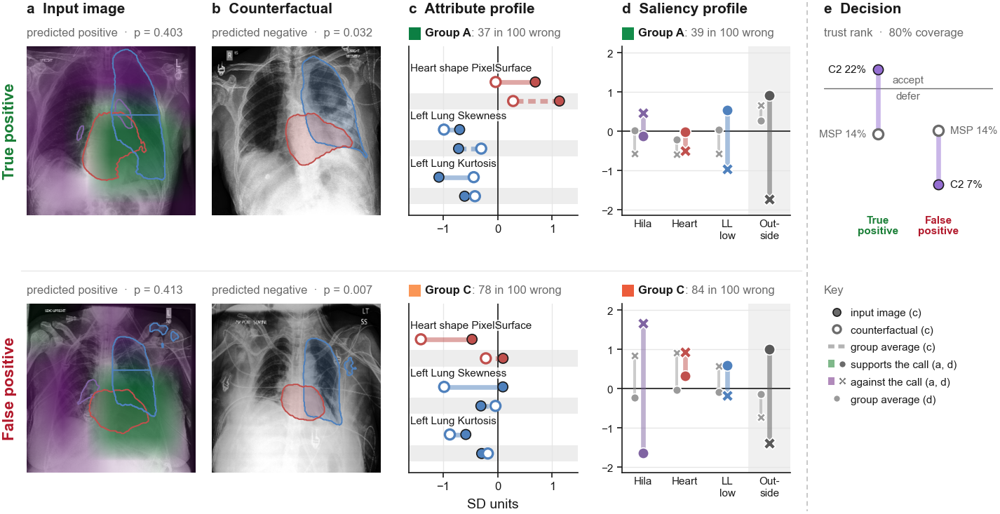

In [70]:
# Pairs for pair_card: a right call in group A of both arms vs a wrong call in a high-error group,
# C0 p within PAIR_TOL, ranked by how well BOTH fit their groups (the worse of the four arm-fits).
# FIT = "contrast": on exactly what pair_card draws (top PC_N_ATTR attributes, image + CF; top
#         PC_N_REG regions + Outside, support + against), how much closer the X-ray sits to its
#         own group's average than to the contrasting group's (A <-> the last group), in SD;
#       "cos": the profile points the way its group's average does (all key attributes / regions);
#       "clear": distance to the nearest other group centre over its own, in the embedding.
PAIR_SIDE  = 1          # 1 = positive calls (TP vs FP), 0 = negative calls (TN vs FN)
PAIR_TOL   = 0.05       # max |p_right - p_wrong|
FIT        = "contrast" # "contrast" | "cos" | "clear"
WRONG_BOTH = True       # True: the wrong call in the last group in BOTH arms
C2_SPLITS  = True       # C2 accepts the right call and defers the wrong one
MSP_SAME   = True       # MSP alone reaches the same verdict on both (it cannot separate them)

def arm_cosine(ns, rows, side, kind):
    """Per row of one arm: cosine between its drawn profile and its group's average profile, both
    in SD units around the average call (d: image + CF on the key attributes; h: support + against
    on the key regions)."""
    k = ns["cluster"][side].loc[rows].values
    if kind == "attr":
        a    = KEY_ATTRS(side)
        prof = pd.concat([ns["zq"][a].add_prefix("img "), ns["zc"][a].add_prefix("cf ")], axis=1)
    else:
        a    = ns["profile_regions"](side)
        prof = pd.concat([ns["ZS"][a].add_prefix("sup "), ns["ZO"][a].add_prefix("opp ")], axis=1)
    cos = np.full(len(rows), np.nan)
    for g in np.unique(k):
        sel  = k == g
        in_k = ns["cluster"][side].index[(ns["cluster"][side] == g).values]
        x, m = prof.loc[rows[sel]].values, prof.loc[in_k].mean().values
        cos[sel] = x @ m / (np.linalg.norm(x, axis=1) * np.linalg.norm(m) + 1e-12)
    return cos

def drawn_profile(ns, side, kind):
    """The values pair_card draws in c (attr) or d (img), one row per X-ray of that arm."""
    if kind == "attr":
        a = KEY_ATTRS(side)[:PC_N_ATTR]
        return pd.concat([ns["zq"][a].add_prefix("img "), ns["zc"][a].add_prefix("cf ")], axis=1)
    regs = [r for r in ns["profile_regions"](side) if r != "Outside"][:PC_N_REG] + ["Outside"]
    return pd.concat([ns["ZS"][regs].add_prefix("sup "), ns["ZO"][regs].add_prefix("opp ")], axis=1)

def arm_contrast(ns, rows, side, kind):
    """Per row: mean |x - other group's average| - mean |x - own group's average| over the drawn
    values (SD). > 0: the drawn profile looks more like its own group than the contrasting one
    (A is contrasted with the last group, every other group with A)."""
    cl   = ns["cluster"][side]
    prof = drawn_profile(ns, side, kind)
    mean = {g: prof.loc[cl.index[(cl == g).values]].mean() for g in np.unique(cl)}
    a_id, last_id = N_CLUSTERS, 1                         # id N = group A, id 1 = most errors
    own  = cl.loc[rows].values
    x    = prof.loc[rows].values
    m_own   = np.stack([mean[g].values for g in own])
    m_other = np.stack([mean[last_id if g == a_id else a_id].values for g in own])
    return np.nanmean(np.abs(x - m_other), axis=1) - np.nanmean(np.abs(x - m_own), axis=1)

def group_fit(rows_attr, rows_img, side):
    """Per X-ray, the worse of its two arms' fits to its own group."""
    if FIT == "contrast":
        fa = arm_contrast(ATTR, rows_attr, side, "attr")
        fi = arm_contrast(SAL,  rows_img,  side, "img")
    elif FIT == "cos":
        fa = arm_cosine(ATTR, rows_attr, side, "attr")
        fi = arm_cosine(SAL,  rows_img,  side, "img")
    else:
        fa, _ = arm_fit(ATTR, rows_attr, side, "attr")
        fi, _ = arm_fit(SAL,  rows_img,  side, "img")
    return np.minimum(fa, fi), fa, fi

def find_pairs(side=PAIR_SIDE, tol=PAIR_TOL, n_show=10):
    thr  = 1 - COVERAGE
    last = LETTERS[N_CLUSTERS - 1]
    h    = J[(J["side"] == side) & J["held_out_attr"] & J["held_out_img"]].copy()
    fit, fa, fi = group_fit(pd.Index(h["row_attr"]), pd.Index(h["row_img"]), side)
    h = h.assign(fit=fit, fit_attr=fa, fit_img=fi).reset_index()

    R = h[(h["correct"] == 1) & (h["group_attr"] == "A") & (h["group_img"] == "A")]
    W = h[(h["correct"] == 0) & (h["group_attr"] != "A") & (h["group_img"] != "A")]
    W = W[(W["group_attr"] == last) & (W["group_img"] == last)] if WRONG_BOTH else \
        W[(W["group_attr"] == last) | (W["group_img"] == last)]
    steps = [f"right in A/A {len(R)}", f"wrong in {last}{'/' + last if WRONG_BOTH else ''} {len(W)}"]
    if C2_SPLITS:
        R, W = R[R["ens_rank"] >= thr], W[W["ens_rank"] < thr]
        steps.append(f"C2 accepts right {len(R)} / defers wrong {len(W)}")

    cols = ["path", "prob", "outcome", "group_attr", "group_img", "ens_rank", "msp_rank",
            "fit", "fit_attr", "fit_img"]
    m = R[cols].merge(W[cols], how="cross", suffixes=("_R", "_W"))
    m["dp"] = (m["prob_R"] - m["prob_W"]).abs()
    if MSP_SAME:
        m = m[(m["msp_rank_R"] >= thr) == (m["msp_rank_W"] >= thr)]
        steps.append(f"MSP same verdict {len(m):,}")
    closest = m["dp"].min() if len(m) else np.nan          # the tightest |dp| the filters allow
    m = m[m["dp"] < tol]
    steps.append(f"pairs |dp| < {tol} {len(m):,}")
    m["pair_fit"] = np.minimum(m["fit_R"], m["fit_W"])
    m = m.sort_values("pair_fit", ascending=False).reset_index(drop=True)
    print(f"{SIDE_NAME[side]}, FIT = {FIT}:  " + "  →  ".join(steps))
    if m.empty:
        print(f"No pair: closest |dp| after the other filters is {closest:.3f}. Raise PAIR_TOL, or "
              f"relax WRONG_BOTH / C2_SPLITS / MSP_SAME, or try PAIR_SIDE = {1 - side}.")
    else:
        display(m.drop(columns=["path_R", "path_W"]).head(n_show).round(3))
    return m

PAIRS = find_pairs()
if len(PAIRS):
    pair_card(PAIRS.loc[0, "path_R"], PAIRS.loc[0, "path_W"])




True positive: p = 0.3533, CF p = 0.0572; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.217 -> accept, MSP rank 0.122 -> defer; CheXpert-v1.0-small/train/patient35693/study3/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient31509/study1/view1_frontal.jpg
False positive: p = 0.3251, CF p = 0.0417; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.001 -> defer, MSP rank 0.108 -> defer; CheXpert-v1.0-small/train/patient14785/study15/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient14714/study1/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_p

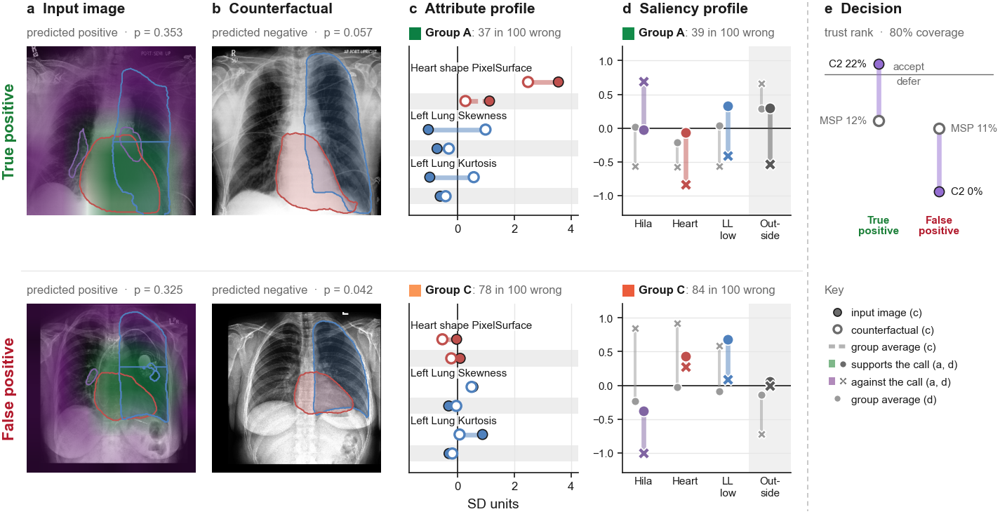

In [65]:
pair_card(PAIRS.loc[1, "path_R"], PAIRS.loc[1, "path_W"])


True positive: p = 0.3944, CF p = 0.0394; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.201 -> accept, MSP rank 0.137 -> defer; CheXpert-v1.0-small/train/patient31359/study3/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient44828/study8/view1_frontal.jpg
False positive: p = 0.4133, CF p = 0.0074; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.073 -> defer, MSP rank 0.144 -> defer; CheXpert-v1.0-small/train/patient18909/study7/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient27301/study9/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_po

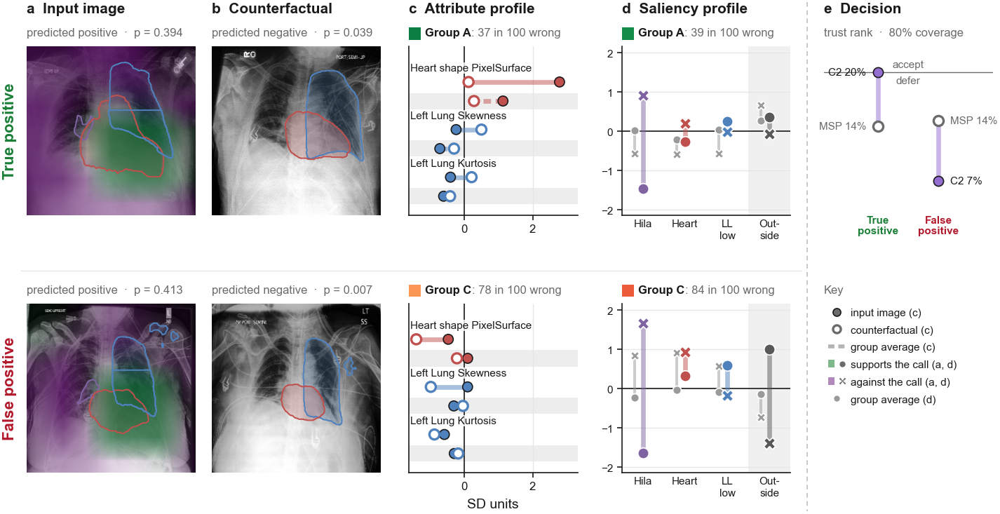

In [67]:
pair_card(PAIRS.loc[2, "path_R"], PAIRS.loc[2, "path_W"])


True positive: p = 0.3533, CF p = 0.0572; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.217 -> accept, MSP rank 0.122 -> defer; CheXpert-v1.0-small/train/patient35693/study3/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient31509/study1/view1_frontal.jpg
False positive: p = 0.3388, CF p = 0.0227; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.088 -> defer, MSP rank 0.115 -> defer; CheXpert-v1.0-small/train/patient29315/study16/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient60071/study3/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_p

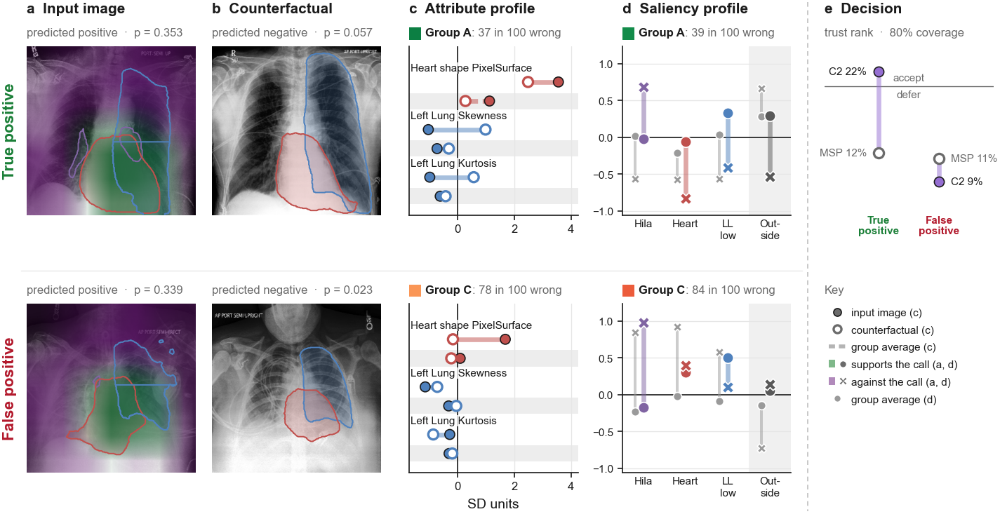

In [71]:
pair_card(PAIRS.loc[3, "path_R"], PAIRS.loc[3, "path_W"])


True positive: p = 0.3533, CF p = 0.0572; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.217 -> accept, MSP rank 0.122 -> defer; CheXpert-v1.0-small/train/patient35693/study3/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient31509/study1/view1_frontal.jpg
False positive: p = 0.3317, CF p = 0.0253; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.096 -> defer, MSP rank 0.112 -> defer; CheXpert-v1.0-small/train/patient50015/study1/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient34917/study1/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_po

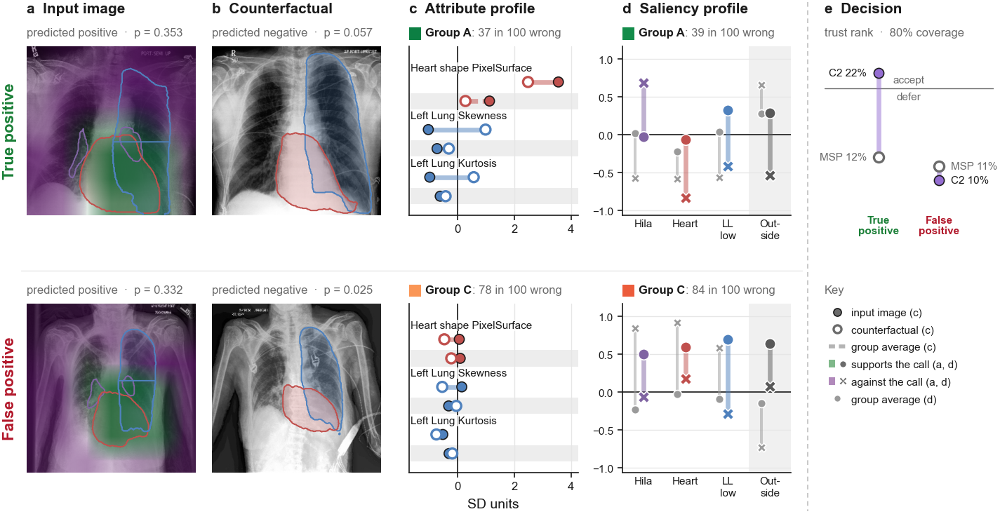

In [73]:
pair_card(PAIRS.loc[4, "path_R"], PAIRS.loc[4, "path_W"])


True positive: p = 0.3533, CF p = 0.0572; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.217 -> accept, MSP rank 0.122 -> defer; CheXpert-v1.0-small/train/patient35693/study3/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient31509/study1/view1_frontal.jpg
False positive: p = 0.3256, CF p = 0.0209; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.110 -> defer, MSP rank 0.109 -> defer; CheXpert-v1.0-small/train/patient52594/study1/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient17442/study4/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_po

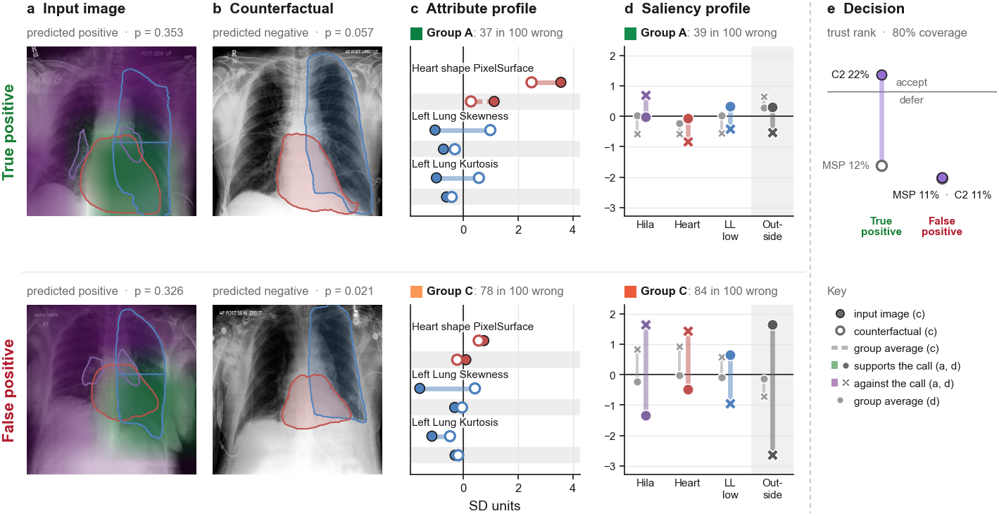

In [74]:
pair_card(PAIRS.loc[5, "path_R"], PAIRS.loc[5, "path_W"])


True positive: p = 0.3533, CF p = 0.0572; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.217 -> accept, MSP rank 0.122 -> defer; CheXpert-v1.0-small/train/patient35693/study3/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient31509/study1/view1_frontal.jpg
False positive: p = 0.3531, CF p = 0.0060; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.113 -> defer, MSP rank 0.121 -> defer; CheXpert-v1.0-small/train/patient20182/study1/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient03427/study1/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_po

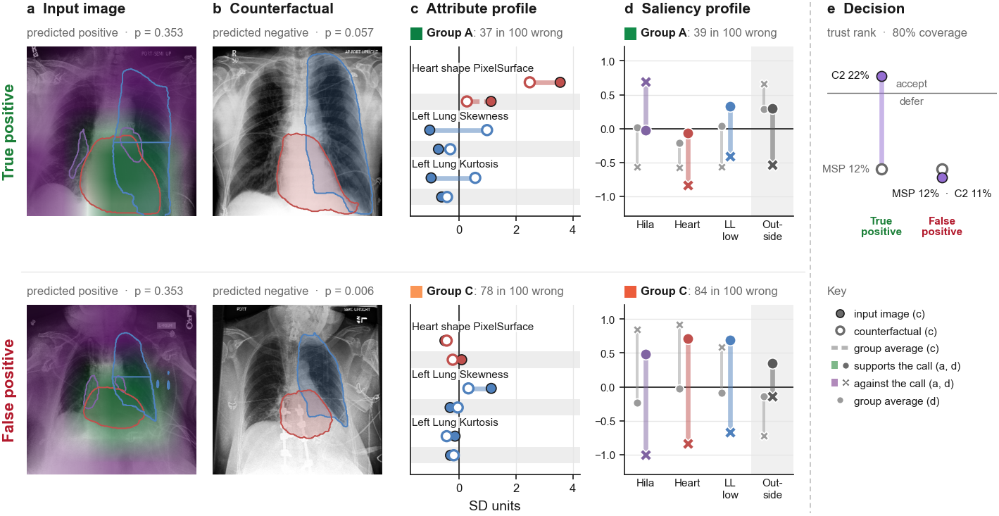

In [75]:
pair_card(PAIRS.loc[6, "path_R"], PAIRS.loc[6, "path_W"])


True positive: p = 0.3713, CF p = 0.0312; attribute group A (C0 wrong 37 in 100), image group A (C0 wrong 39 in 100); C2 rank 0.213 -> accept, MSP rank 0.129 -> defer; CheXpert-v1.0-small/train/patient44562/study1/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient45293/study3/view1_frontal.jpg
False positive: p = 0.3531, CF p = 0.0060; attribute group C (C0 wrong 78 in 100), image group C (C0 wrong 84 in 100); C2 rank 0.113 -> defer, MSP rank 0.121 -> defer; CheXpert-v1.0-small/train/patient20182/study1/view1_frontal.jpg | cf CheXpert-v1.0-small/train/patient03427/study1/view1_frontal.jpg
d shows WHERE C0's evidence concentrates in each region, relative to the typical call of this side (log10 enrichment, SD units), not HOW MUCH evidence there is: each map is scaled to its own maximum, so +1 SD can be a faint smear next to a strong blob elsewhere.
Coverage 80%; C2 = ens_lr of MLP_I+C+D + dual_sal, K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_pair_po

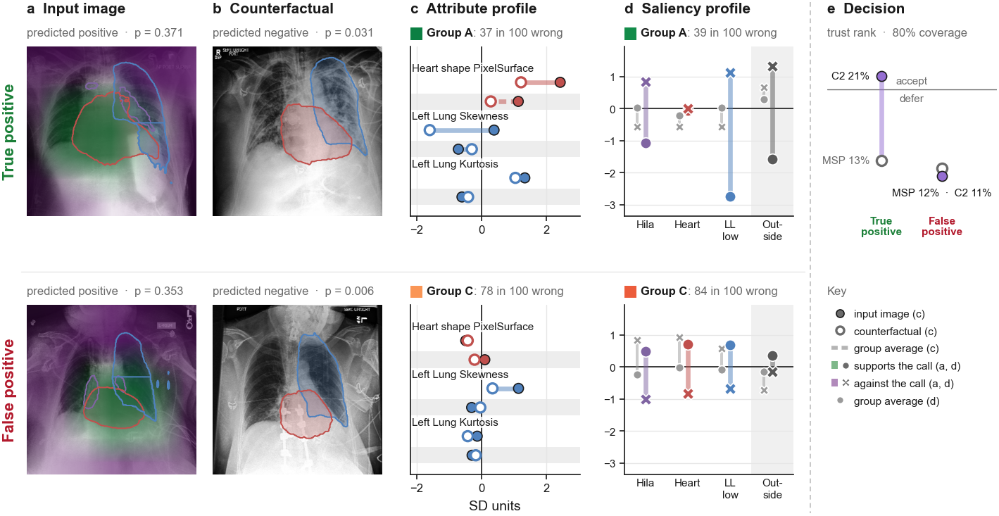

In [76]:
pair_card(PAIRS.loc[7, "path_R"], PAIRS.loc[7, "path_W"])


In [ ]:
# The pairs in the thesis, redrawn with the current code into one folder (figures/xai/
# thesis_pair_cards), whatever PAIR_TOL is: both have |dp| > 0.03 (cardiomegaly 0.041, effusion 0.036).
# One kernel draws one disease: run with DISEASE = "cardiomegaly", then again with "effusion".
THESIS_PAIRS = {
    "cardiomegaly": ("CheXpert-v1.0-small/train/patient35693/study3/view1_frontal.jpg",    # TP
                     "CheXpert-v1.0-small/train/patient48273/study1/view1_frontal.jpg"),   # FP
    "effusion":     ("CheXpert-v1.0-small/train/patient51459/study1/view1_frontal.jpg",    # TP
                     "CheXpert-v1.0-small/train/patient56111/study1/view1_frontal.jpg"),   # FP
}
if DISEASE in THESIS_PAIRS:
    _fig_dir, FIG_DIR = FIG_DIR, os.path.join("figures", "xai", "thesis_pair_cards")
    try:
        pair_card(*THESIS_PAIRS[DISEASE])
    finally:
        FIG_DIR = _fig_dir
else:
    print(f"no thesis pair for {DISEASE}")


---

## 5. Cards

Each cell picks one X-ray and draws its card. Change the filters to choose another case, `nth` to
step through the candidates, or pass any path of `J` straight to `combined_card`.

positive calls, fold 4 4,800  →  held out in both arms 2,482  →  C0 wrong 1,563  →  C2 defers 1,305  →  MSP would accept 31  →  both arms defer 26
8 candidates with a typical profile in both arms


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,clear_attr,clear_img,gap_attr,gap_img,clearness
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient15940/study3/view1_frontal.jpg,FP,B,B,0.162,0.158,0.172,0.215,3.336,2.854,0.358,0.473,2.854
CheXpert-v1.0-small/train/patient14640/study1/view1_frontal.jpg,FP,B,B,0.173,0.157,0.198,0.230,2.538,2.583,0.604,0.504,2.538
CheXpert-v1.0-small/train/patient11719/study3/view1_frontal.jpg,FP,B,B,0.153,0.140,0.177,0.211,1.550,2.665,0.570,0.500,1.550
CheXpert-v1.0-small/train/patient39993/study2/view1_frontal.jpg,FP,B,B,0.175,0.166,0.191,0.232,1.371,2.528,0.458,0.552,1.371
CheXpert-v1.0-small/train/patient52619/study1/view1_frontal.jpg,FP,B,B,0.131,0.078,0.191,0.210,1.129,1.411,0.454,0.286,1.129


C0 says cardiomegaly (p = 0.68, FP)  →  counterfactual p = 0.04
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 defers (rank 16%), MSP alone would accept (rank 21%); attribute C2 rank 16%, image C2 rank 17%
Attribute arm, group B: 63 in 100 positive calls wrong, vs 64 in 100 for other positive calls
Saliency arm, group B: 61 in 100 positive calls wrong, vs 66 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/cardiomegaly/k4/cardiomegaly_knn_correct_cf_combined_case_positive_FP_attrB_imgB_C2defer_MSPaccept_cov80_row79236.{pdf,png,txt}


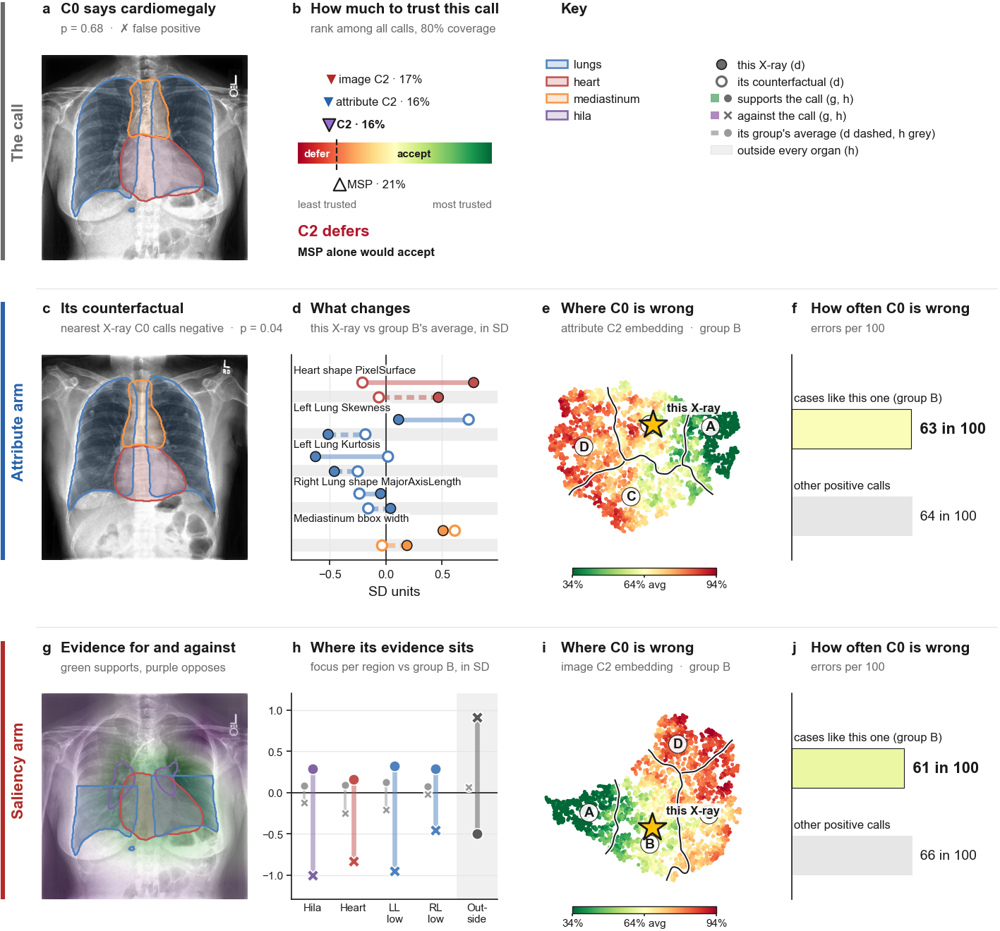

In [19]:
# The mock-up's case: C0 wrong on a positive call, C2 defers it (both arms agree), MSP alone would
# have accepted it. C2 and MSP only disagree close to the cut (cardiomegaly: C2 rank 0.17-0.20 vs
# MSP 0.20-0.22), so the default margin of 0.05 leaves no such case; 0.01 keeps them.
combined_card(pick_combined(1, "wrong", verdict="defer", msp="disagree", arms="agree", margin=0.01))

positive calls, fold 4 4,800  →  held out in both arms 2,482  →  C0 correct 919  →  C2 accepts 132  →  MSP would accept 119  →  both arms accept 119  →  attribute group A 119  →  image group A 115
35 candidates with a typical profile in both arms


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,clear_attr,clear_img,gap_attr,gap_img,clearness
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient39279/study1/view1_frontal.jpg,TP,A,A,0.256,0.258,0.261,0.298,4.208,4.147,0.531,0.266,4.147
CheXpert-v1.0-small/train/patient53050/study2/view1_frontal.jpg,TP,A,A,0.259,0.266,0.247,0.309,3.968,5.386,0.404,0.303,3.968
CheXpert-v1.0-small/train/patient04248/study10/view1_frontal.jpg,TP,A,A,0.261,0.268,0.255,0.309,4.008,3.589,0.386,0.155,3.589
CheXpert-v1.0-small/train/patient26426/study2/view1_frontal.jpg,TP,A,A,0.265,0.280,0.242,0.363,3.566,6.230,0.491,0.168,3.566
CheXpert-v1.0-small/train/patient41748/study1/view1_frontal.jpg,TP,A,A,0.254,0.256,0.257,0.305,4.289,3.342,0.500,0.328,3.342


KeyboardInterrupt: 

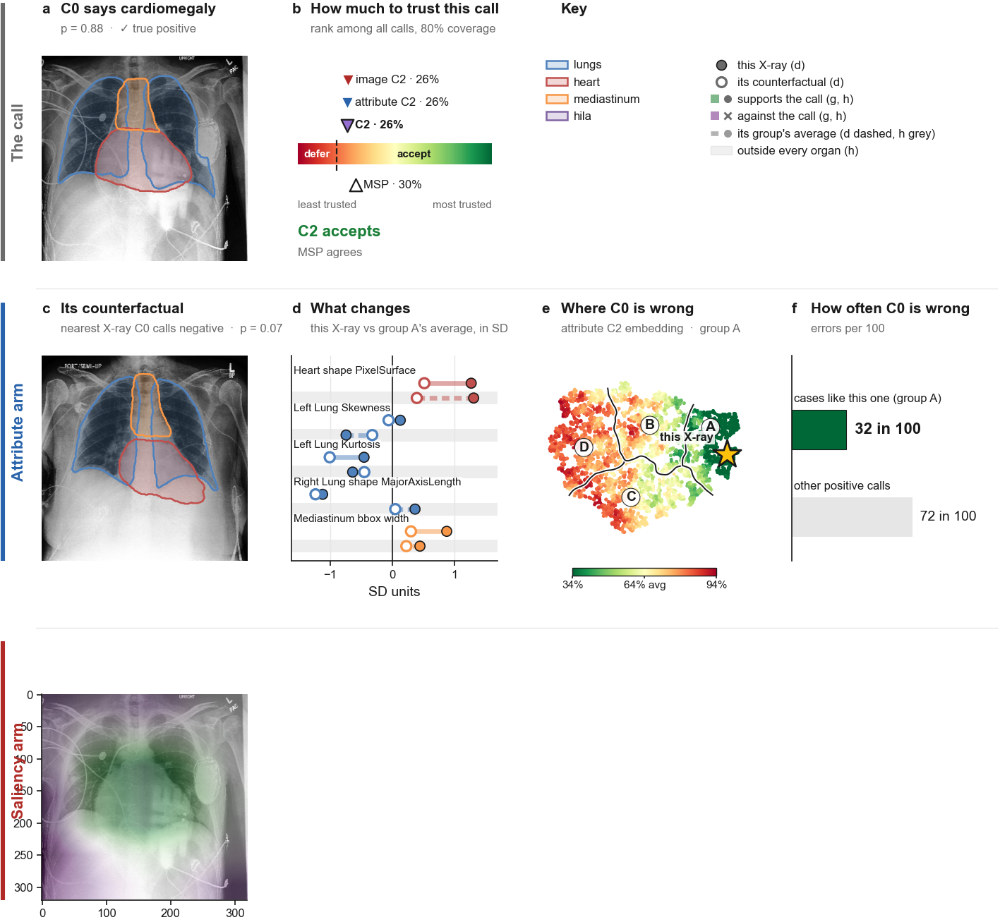

In [20]:
# A reliable case: lowest-error group in both arms, C0 right, C2 and MSP both accept.
combined_card(pick_combined(1, "correct", verdict="accept", msp="agree", arms="agree",
                            group_attr="A", group_img="A"))

positive calls, fold 4 9,143  →  held out in an arm 4,436  →  C0 wrong 1,265  →  C2 defers 745  →  MSP would accept 118  →  both arms defer 60  →  attribute group C 58  →  image group B 1
1 candidates with a typical profile in both arms


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,clear_attr,clear_img,gap_attr,gap_img,clearness
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient07378/study3/view1_frontal.jpg,FP,C,B,0.084,0.05,0.152,0.258,3.656,1.032,0.668,0.683,1.032


C0 says effusion (p = 0.71, FP)  →  counterfactual p = 0.32
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 defers (rank 8%), MSP alone would accept (rank 26%); attribute C2 rank 5%, image C2 rank 15%
Attribute arm, group C: 43 in 100 positive calls wrong, vs 15 in 100 for other positive calls
Saliency arm, group B: 20 in 100 positive calls wrong, vs 33 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/effusion/effusion_knn_correct_cf_combined_case_positive_FP_attrC_imgB_C2defer_MSPaccept_cov80_row75060.{pdf,png,txt}


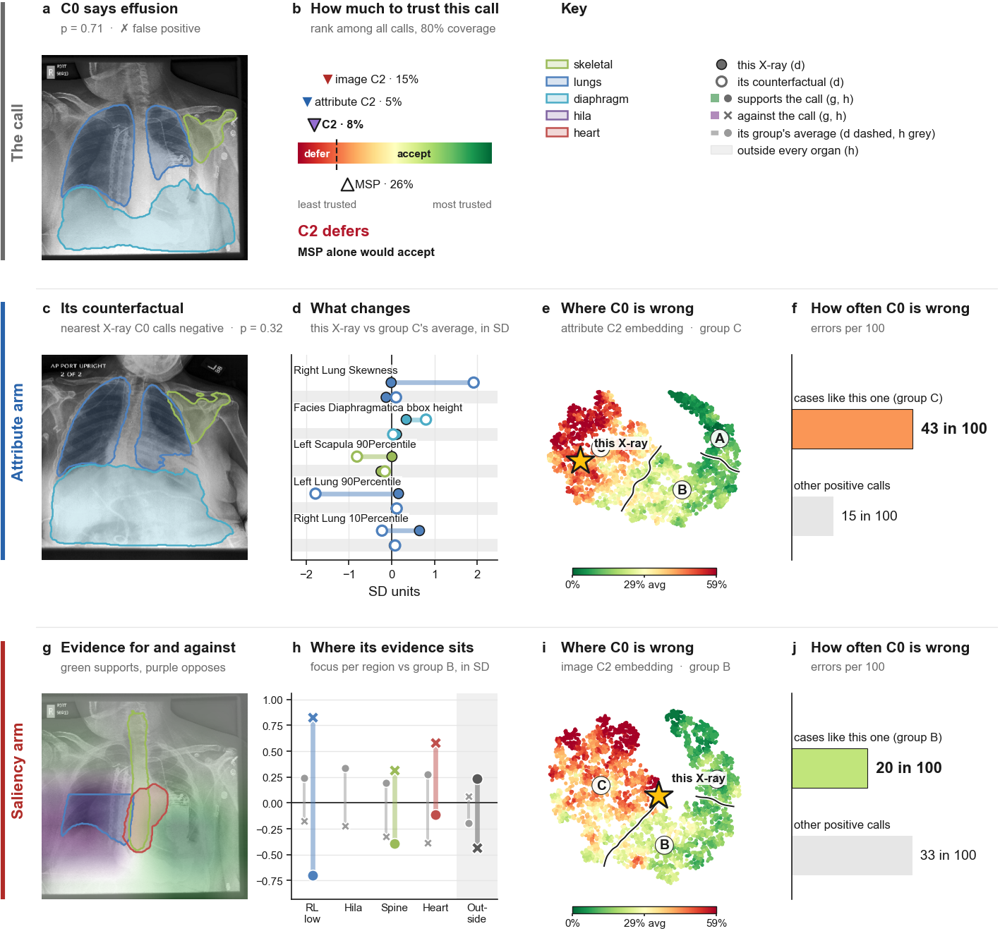

In [ ]:
combined_card(pick_combined(1, "wrong", verdict="defer", msp="disagree", arms="agree",
                            margin=0.005, held_out="any", group_attr="C", group_img="B"))



positive calls, fold 4 9,143  →  held out in an arm 4,436  →  C0 wrong 1,265  →  C2 defers 745  →  MSP would accept 118  →  both arms defer 60  →  attribute group C 58  →  image group B 1
1 candidates with a typical profile in both arms


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,clear_attr,clear_img,gap_attr,gap_img,clearness
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient07378/study3/view1_frontal.jpg,FP,C,B,0.084,0.05,0.152,0.258,3.656,1.032,0.668,0.683,1.032


C0 says effusion (p = 0.71, FP)  →  counterfactual p = 0.32
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 defers (rank 8%), MSP alone would accept (rank 26%); attribute C2 rank 5%, image C2 rank 15%
Attribute arm, group C: 43 in 100 positive calls wrong, vs 15 in 100 for other positive calls
Saliency arm, group B: 20 in 100 positive calls wrong, vs 33 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/effusion/effusion_knn_correct_cf_combined_case_positive_FP_attrC_imgB_C2defer_MSPaccept_cov80_row75060.{pdf,png,txt}


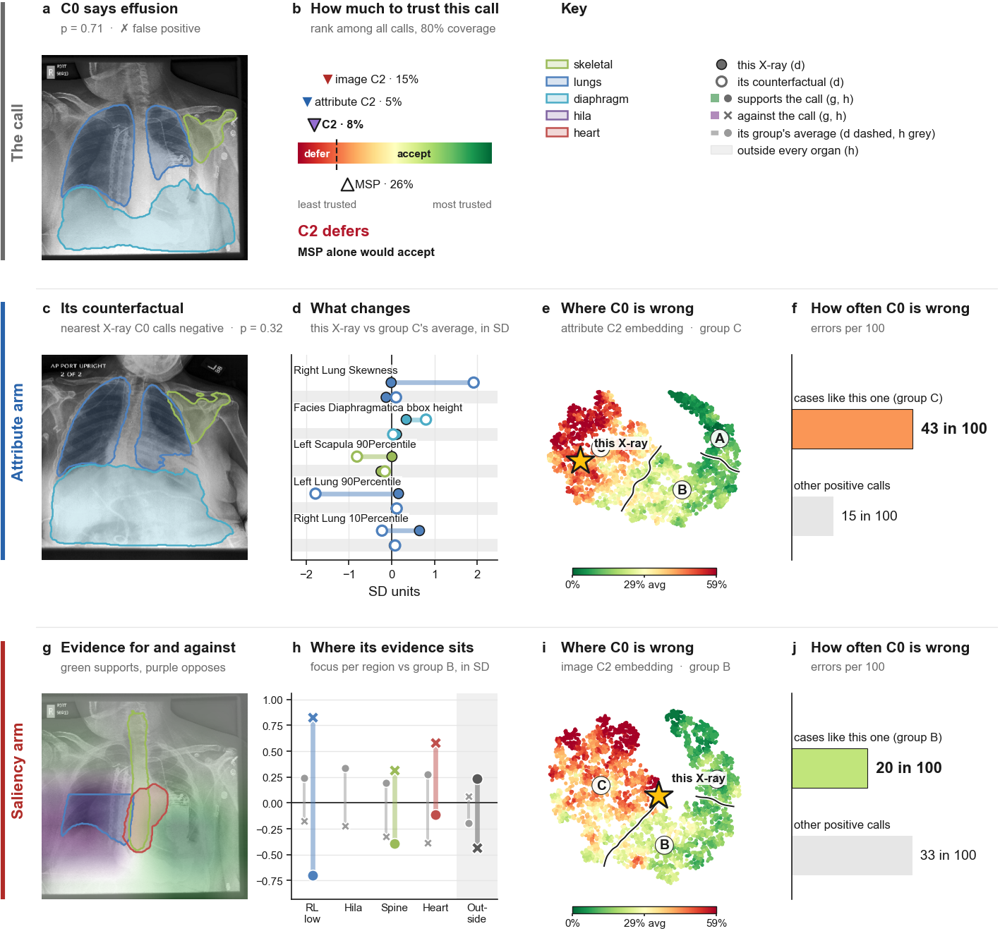

In [ ]:
combined_card(pick_combined(1, "wrong", verdict="defer", msp="disagree", arms="agree",
                            margin=0.005, held_out="any", group_attr="C", group_img="B"))


positive calls, fold 4 9,143  →  held out in both arms 4,436  →  C0 correct 3,171  →  C2 accepts 2,224  →  MSP would defer 68  →  both arms accept 49
14 candidates with a typical profile in both arms


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,clear_attr,clear_img,gap_attr,gap_img,clearness
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient24021/study18/view1_frontal.jpg,TP,C,C,0.221,0.233,0.219,0.180,4.045,3.021,0.280,0.468,3.021
CheXpert-v1.0-small/train/patient21707/study1/view1_frontal.jpg,TP,C,C,0.224,0.236,0.221,0.156,2.381,2.375,0.647,0.610,2.375
CheXpert-v1.0-small/train/patient23920/study8/view1_frontal.jpg,TP,B,C,0.277,0.321,0.203,0.171,2.052,1.944,0.527,0.570,1.944
CheXpert-v1.0-small/train/patient01165/study11/view1_frontal.jpg,TP,C,C,0.214,0.213,0.234,0.123,1.867,2.362,0.598,0.509,1.867
CheXpert-v1.0-small/train/patient33078/study6/view1_frontal.jpg,TP,C,C,0.233,0.213,0.292,0.165,2.433,1.803,0.700,0.642,1.803


C0 says effusion (p = 0.64, TP)  →  counterfactual p = 0.09
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 accepts (rank 22%), MSP alone would defer (rank 18%); attribute C2 rank 23%, image C2 rank 22%
Attribute arm, group C: 43 in 100 positive calls wrong, vs 15 in 100 for other positive calls
Saliency arm, group C: 43 in 100 positive calls wrong, vs 16 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/effusion/effusion_knn_correct_cf_combined_case_positive_TP_attrC_imgC_C2accept_MSPdefer_cov80_row80290.{pdf,png,txt}


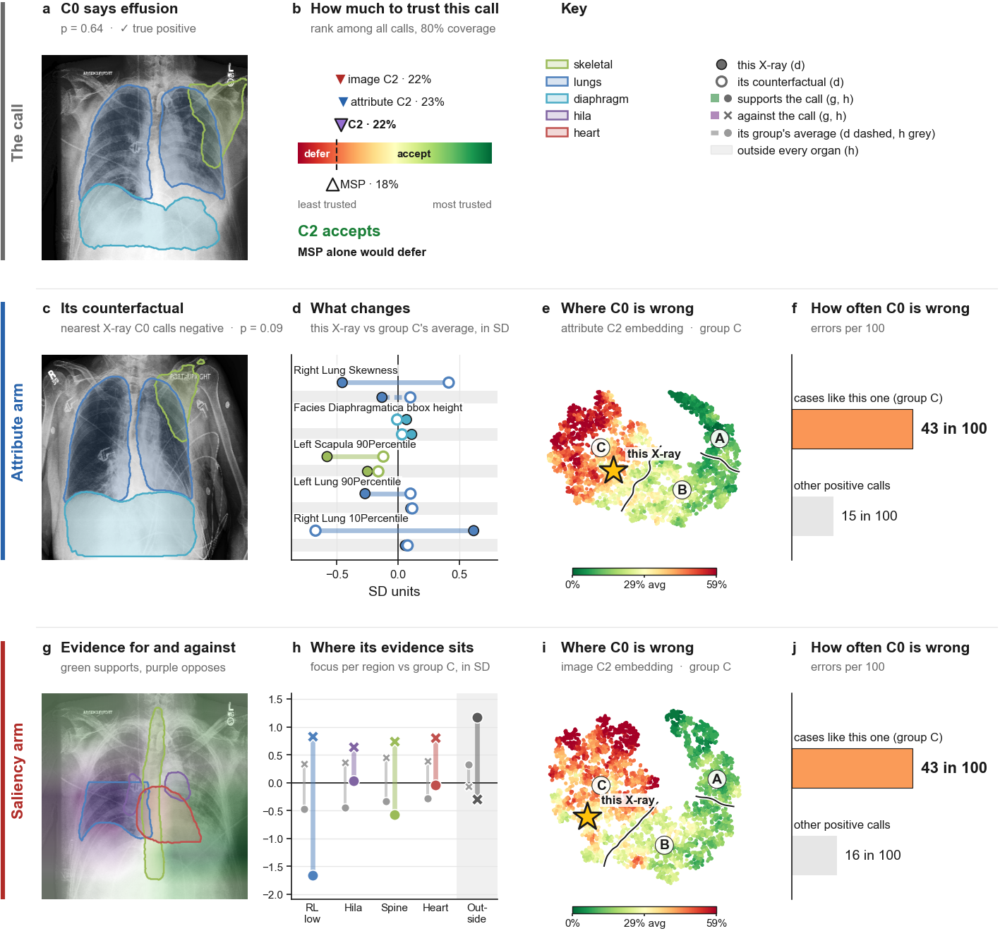

In [ ]:
# Where C2 adds to MSP: C0 right, C2 accepts it (both arms agree), MSP alone would defer it. Close
# to the cut again, hence the small margin.
combined_card(pick_combined(1, "correct", verdict="accept", msp="disagree", arms="agree", margin=0.01))

negative calls, fold 4 9,104  →  held out in both arms 4,519  →  C0 wrong 550  →  attribute group C 446  →  image group C 338
93 candidates with a typical profile in both arms


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,clear_attr,clear_img,gap_attr,gap_img,clearness
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient30514/study11/view1_frontal.jpg,FN,C,C,0.367,0.365,0.385,0.338,5.849,4.462,0.470,0.750,4.462
CheXpert-v1.0-small/train/patient05224/study2/view1_frontal.jpg,FN,C,C,0.286,0.280,0.314,0.260,4.429,4.544,0.608,0.909,4.429
CheXpert-v1.0-small/train/patient18344/study4/view1_frontal.jpg,FN,C,C,0.279,0.282,0.296,0.222,4.528,4.338,0.456,0.586,4.338
CheXpert-v1.0-small/train/patient47924/study2/view1_frontal.jpg,FN,C,C,0.386,0.413,0.347,0.269,6.529,4.100,0.507,0.667,4.100
CheXpert-v1.0-small/train/patient49179/study5/view1_frontal.jpg,FN,C,C,0.281,0.304,0.250,0.219,4.078,5.338,0.671,0.933,4.078


C0 says no effusion (p = 0.24, FN)  →  counterfactual p = 0.79
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 accepts (rank 37%), MSP alone would accept (rank 34%); attribute C2 rank 36%, image C2 rank 39%
Attribute arm, group C: 23 in 100 negative calls wrong, vs 4 in 100 for other negative calls
Saliency arm, group C: 27 in 100 negative calls wrong, vs 6 in 100 for other negative calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/effusion/effusion_knn_correct_cf_combined_case_negative_FN_attrC_imgC_C2accept_MSPaccept_cov80_row82221.{pdf,png,txt}


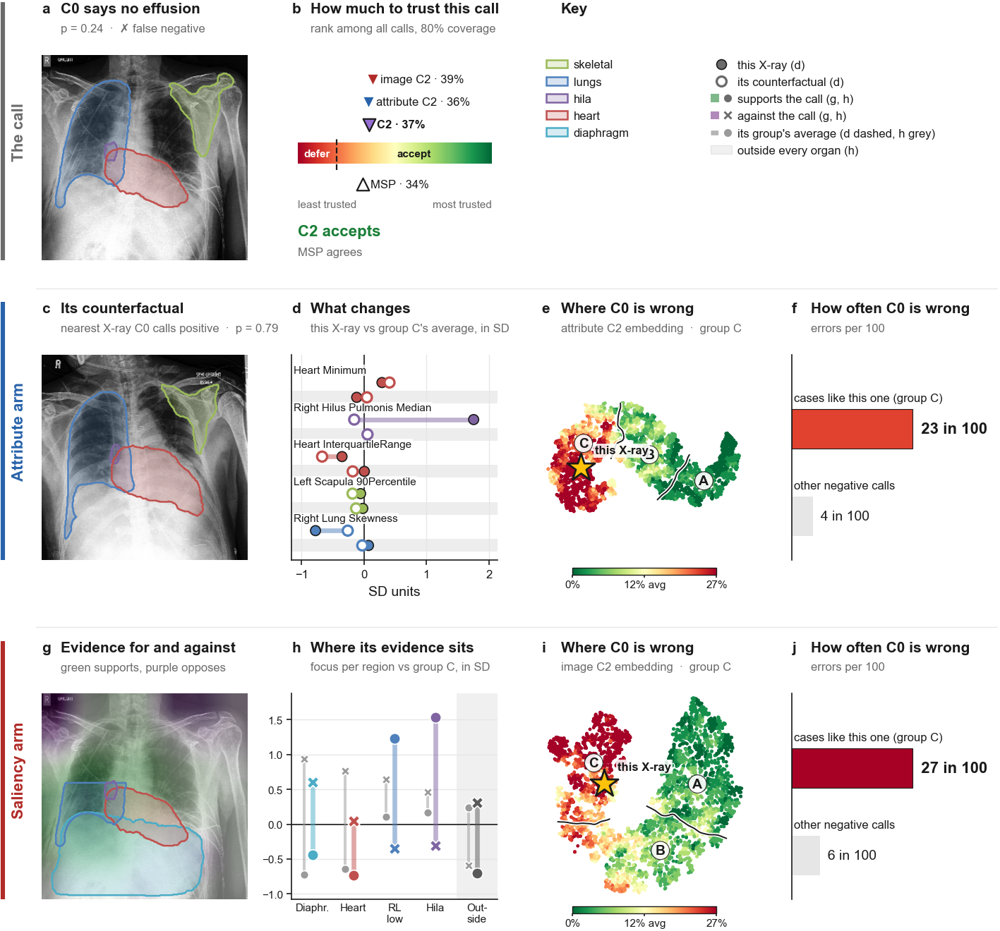

In [ ]:
# A missed case: C0 says negative and is wrong, highest-error group in both arms. No verdict filter:
# when the global cut does not reach the negative calls (cardiomegaly at 80%), a deferred false
# negative does not exist (see "What exists").
combined_card(pick_combined(0, "wrong", group_attr=LETTERS[N_CLUSTERS - 1],
                            group_img=LETTERS[N_CLUSTERS - 1]))

positive calls, fold 4 4,800  →  held out in an arm 2,482  →  C0 wrong 1,563  →  C2 defers 1,336  →  MSP would accept 47  →  both arms defer 38  →  attribute group C 8  →  image group B 5
5 candidates, most group-like in both arms first


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,cos_attr,cos_img,clear_attr,clear_img,cosine
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient38305/study2/view1_frontal.jpg,FP,C,B,0.178,0.189,0.142,0.212,0.646,NaN,2.387,1.037,0.646
CheXpert-v1.0-small/train/patient24713/study4/view1_frontal.jpg,FP,C,B,0.163,0.167,0.153,0.205,0.851,0.487,1.064,2.464,0.487
CheXpert-v1.0-small/train/patient21910/study1/view1_frontal.jpg,FP,C,B,0.193,0.193,0.189,0.223,0.382,0.874,1.826,1.827,0.382
CheXpert-v1.0-small/train/patient17692/study1/view1_frontal.jpg,FP,C,B,0.183,0.177,0.193,0.208,0.467,0.085,1.362,1.760,0.085
CheXpert-v1.0-small/train/patient55067/study1/view1_frontal.jpg,FP,C,B,0.194,0.195,0.183,0.205,0.083,-0.043,0.967,1.218,-0.043


C0 says cardiomegaly (p = 0.67, FP)  →  counterfactual p = 0.16
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 defers (rank 18%), MSP alone would accept (rank 21%); attribute C2 rank 19%, image C2 rank 14%
Attribute arm, group C: 70 in 100 positive calls wrong, vs 62 in 100 for other positive calls
Saliency arm, group B: 61 in 100 positive calls wrong, vs 66 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/cardiomegaly/k4/cardiomegaly_knn_correct_cf_combined_case_positive_FP_attrC_imgB_C2defer_MSPaccept_cov80_row86759.{pdf,png,txt}


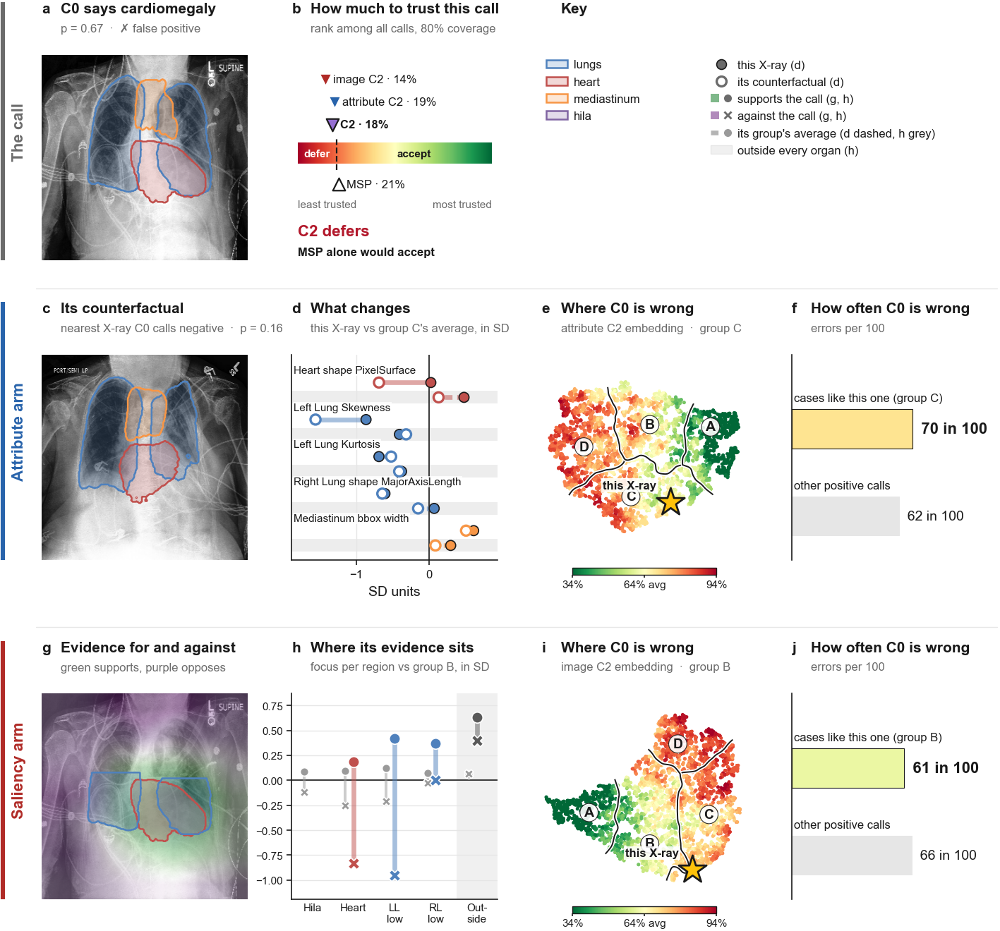

In [21]:
# pick_combined with candidates ranked by whether their drawn profile POINTS the way their group's
# average does (cosine similarity), not by how close it is to it. Distance favours calls near zero,
# whose flat profiles look like nothing; cosine ignores size and checks the direction: above or
# below the average call on the same attributes / regions.

def arm_cosine(ns, rows, side, kind):
    """Per row of one arm: cosine between its drawn profile and its group's average profile, both
    in SD units around the average call (d: image + CF on the key attributes; h: support + against
    on the key regions)."""
    k = ns["cluster"][side].loc[rows].values
    if kind == "attr":
        a    = KEY_ATTRS(side)
        prof = pd.concat([ns["zq"][a].add_prefix("img "), ns["zc"][a].add_prefix("cf ")], axis=1)
    else:
        a    = ns["profile_regions"](side)
        prof = pd.concat([ns["ZS"][a].add_prefix("sup "), ns["ZO"][a].add_prefix("opp ")], axis=1)
    cos = np.full(len(rows), np.nan)
    for g in np.unique(k):
        sel  = k == g
        in_k = ns["cluster"][side].index[(ns["cluster"][side] == g).values]
        x, m = prof.loc[rows[sel]].values, prof.loc[in_k].mean().values
        cos[sel] = x @ m / (np.linalg.norm(x, axis=1) * np.linalg.norm(m) + 1e-12)
    return cos

def pick_combined_cos(side, outcome=None, verdict=None, msp=None, arms=None, group_attr=None,
                      group_img=None, held_out="both", margin=0.05, n_show=5, nth=0):
    """As pick_combined, same filters; candidates ranked by the SMALLER of the two arms' cosines
    (most group-like in both arms first). Clearness is shown for reference, not used."""
    thr  = 1 - COVERAGE
    flip = {"accept": "defer", "defer": "accept"}
    on   = lambda r, cut, m: (r >= thr + m) if cut == "accept" else (r < thr - m)
    c, steps = J[J["side"] == side], []
    steps.append((f"{SIDE_NAME[side].lower()}, fold {EMB_FOLD}", len(c)))

    def keep(label, mask):
        nonlocal c
        c = c[np.asarray(mask)]
        steps.append((label, len(c)))

    if held_out == "both":
        keep("held out in both arms", c["held_out_attr"] & c["held_out_img"])
    elif held_out == "any":
        keep("held out in an arm", c["held_out_attr"] | c["held_out_img"])
    if outcome in ("correct", "wrong"):
        keep(f"C0 {outcome}", c["correct"] == (outcome == "correct"))
    elif outcome is not None:
        keep(outcome, c["outcome"] == outcome)
    if verdict is not None:
        keep(f"C2 {verdict}s", on(c["ens_rank"], verdict, margin))
    if msp in ("agree", "disagree"):
        assert verdict, "msp='agree' / 'disagree' needs a verdict"
        cut = verdict if msp == "agree" else flip[verdict]
        keep(f"MSP would {cut}", on(c["msp_rank"], cut, margin))
    elif msp is not None:
        keep(f"MSP would {msp}", on(c["msp_rank"], msp, margin))
    if arms == "agree":
        assert verdict, "arms='agree' needs a verdict"
        keep(f"both arms {verdict}", on(c["rank_attr"], verdict, 0) & on(c["rank_img"], verdict, 0))
    elif arms == "split":
        keep("arms split", (c["rank_attr"] >= thr) != (c["rank_img"] >= thr))
    if group_attr is not None:
        keep(f"attribute group {group_attr}", c["group_attr"] == group_attr)
    if group_img is not None:
        keep(f"image group {group_img}", c["group_img"] == group_img)

    print("  →  ".join(f"{label} {n:,}" for label, n in steps))
    if not len(c):
        print("no X-ray passes every filter: relax the one that emptied the pool (above)")
        return None

    rows_a, rows_i = pd.Index(c["row_attr"]), pd.Index(c["row_img"])
    cos_a, cos_i   = arm_cosine(ATTR, rows_a, side, "attr"), arm_cosine(SAL, rows_i, side, "img")
    clr_a, _       = arm_fit(ATTR, rows_a, side, "attr")
    clr_i, _       = arm_fit(SAL,  rows_i, side, "img")
    score = c[["outcome", "group_attr", "group_img", "ens_rank", "rank_attr", "rank_img",
               "msp_rank"]].assign(cos_attr=cos_a, cos_img=cos_i, clear_attr=clr_a, clear_img=clr_i)
    score["cosine"] = np.fmin(cos_a, cos_i)
    score = score.sort_values("cosine", ascending=False)
    print(f"{len(score)} candidates, most group-like in both arms first")
    display(score.head(max(n_show, nth + 1)).round(3))
    return score.index[nth]

combined_card(pick_combined_cos(1, "wrong", verdict="defer", msp="disagree", arms="agree",
                                margin=0.005, held_out="any", group_attr="C", group_img="B"))


In [23]:
combined_card(pick_combined_cos(1, "wrong", verdict="defer", msp="disagree", arms="agree",
                                margin=0.005, held_out="any", group_attr="C", group_img="D", nth=1))


positive calls, fold 4 4,800  →  held out in an arm 2,482  →  C0 wrong 1,563  →  C2 defers 1,336  →  MSP would accept 47  →  both arms defer 38  →  attribute group C 8  →  image group D 0
no X-ray passes every filter: relax the one that emptied the pool (above)
no card drawn


positive calls, fold 4 4,800  →  held out in an arm 2,482  →  C0 wrong 1,563  →  C2 defers 1,336  →  MSP would accept 47  →  both arms defer 38  →  attribute group C 11  →  image group B 9
9 candidates, most group-like in both arms first


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,cos_attr,cos_img,clear_attr,clear_img,cosine
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient11719/study3/view1_frontal.jpg,FP,C,B,0.153,0.140,0.177,0.211,0.593,0.454,1.116,1.589,0.454
CheXpert-v1.0-small/train/patient49667/study1/view1_frontal.jpg,FP,C,B,0.147,0.164,0.093,0.205,0.324,0.254,1.036,2.479,0.254
CheXpert-v1.0-small/train/patient08516/study2/view1_frontal.jpg,FP,C,B,0.083,0.115,0.019,0.207,0.547,0.252,1.915,1.782,0.252
CheXpert-v1.0-small/train/patient36771/study13/view1_frontal.jpg,FP,C,B,0.173,0.177,0.163,0.206,0.210,0.168,1.173,1.647,0.168
CheXpert-v1.0-small/train/patient33799/study1/view1_frontal.jpg,FP,C,B,0.170,0.173,0.162,0.265,0.109,0.015,1.028,2.005,0.015


C0 says cardiomegaly (p = 0.65, FP)  →  counterfactual p = 0.04
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 defers (rank 8%), MSP alone would accept (rank 21%); attribute C2 rank 12%, image C2 rank 2%
Attribute arm, group C: 78 in 100 positive calls wrong, vs 56 in 100 for other positive calls
Saliency arm, group B: 70 in 100 positive calls wrong, vs 58 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/cardiomegaly/cardiomegaly_knn_correct_cf_combined_case_positive_FP_attrC_imgB_C2defer_MSPaccept_cov80_row76748.{pdf,png,txt}


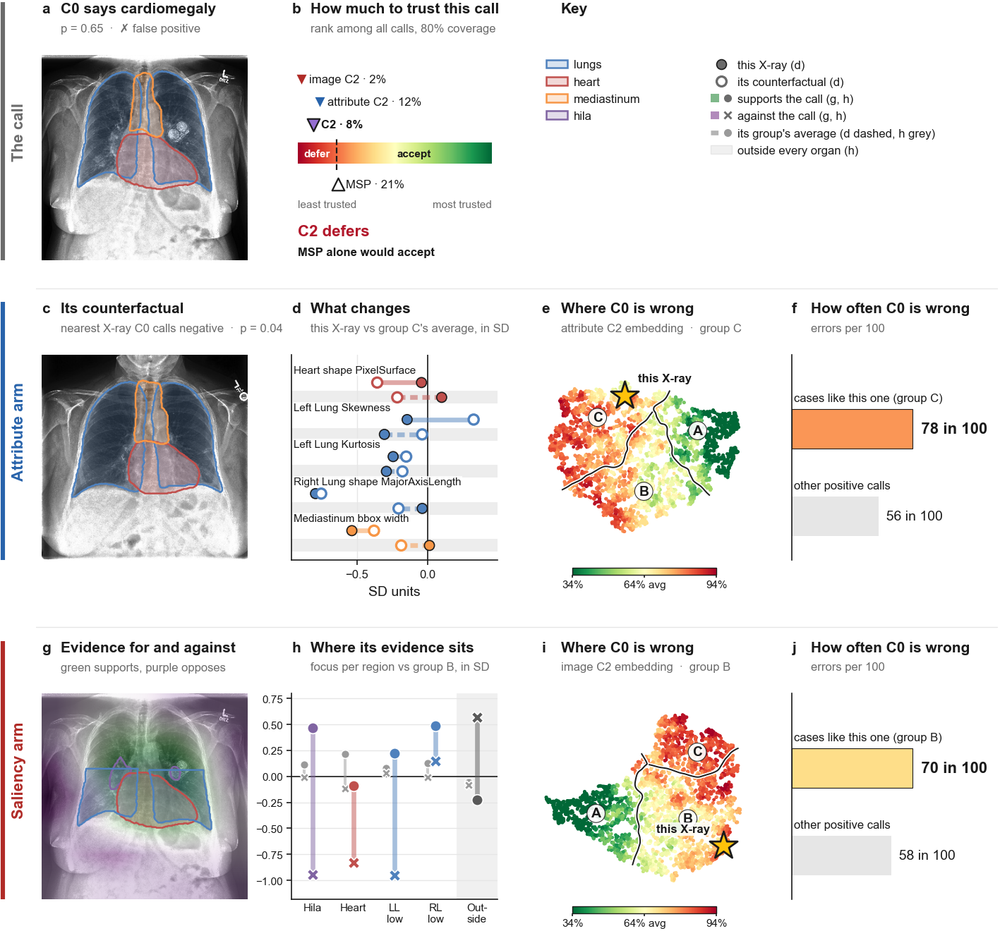

In [ ]:
combined_card(pick_combined_cos(1, "wrong", verdict="defer", msp="disagree", arms="agree",
                                margin=0.005, held_out="any", group_attr="C", group_img="B", nth=2))

positive calls, fold 4 9,143  →  held out in an arm 4,436  →  C0 wrong 1,265  →  C2 defers 745  →  MSP would accept 118  →  both arms defer 60  →  attribute group C 58  →  image group C 57
57 candidates, most group-like in both arms first


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,cos_attr,cos_img,clear_attr,clear_img,cosine
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient37172/study2/view1_frontal.jpg,FP,C,C,0.138,0.126,0.175,0.242,0.693,0.711,3.097,2.423,0.693
CheXpert-v1.0-small/train/patient11037/study6/view1_frontal.jpg,FP,C,C,0.126,0.137,0.120,0.303,0.664,0.667,3.815,2.996,0.664
CheXpert-v1.0-small/train/patient54705/study1/view1_frontal.jpg,FP,C,C,0.127,0.172,0.066,0.232,0.606,0.917,2.538,2.986,0.606
CheXpert-v1.0-small/train/patient21585/study23/view1_frontal.jpg,FP,C,C,0.031,0.045,0.036,0.222,0.508,NaN,7.585,2.283,0.508
CheXpert-v1.0-small/train/patient13732/study5/view1_frontal.jpg,FP,C,C,0.091,0.084,0.121,0.234,0.470,NaN,4.700,4.629,0.470


C0 says effusion (p = 0.69, FP)  →  counterfactual p = 0.08
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 defers (rank 13%), MSP alone would accept (rank 23%); attribute C2 rank 17%, image C2 rank 7%
Attribute arm, group C: 43 in 100 positive calls wrong, vs 15 in 100 for other positive calls
Saliency arm, group C: 43 in 100 positive calls wrong, vs 16 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/effusion/effusion_knn_correct_cf_combined_case_positive_FP_attrC_imgC_C2defer_MSPaccept_cov80_row89696.{pdf,png,txt}


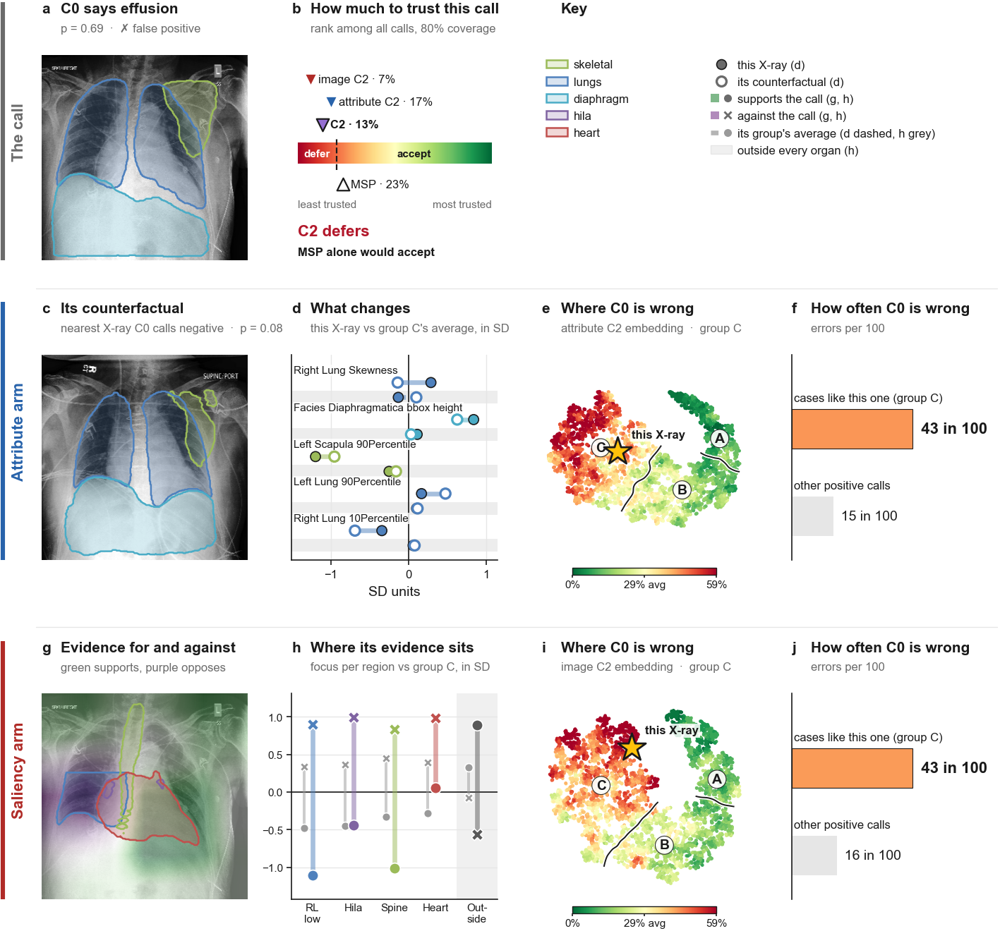

In [ ]:
combined_card(pick_combined_cos(1, "wrong", verdict="defer", msp="disagree", arms="agree",
                                margin=0.005, held_out="any", group_attr="C", group_img="C", nth=2))


positive calls, fold 4 9,143  →  held out in an arm 4,436  →  C0 wrong 1,265  →  C2 defers 745  →  MSP would accept 118  →  both arms defer 60  →  attribute group C 58  →  image group C 57
57 candidates, most group-like in both arms first


,outcome,group_attr,group_img,ens_rank,rank_attr,rank_img,msp_rank,cos_attr,cos_img,clear_attr,clear_img,cosine
path,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient37172/study2/view1_frontal.jpg,FP,C,C,0.138,0.126,0.175,0.242,0.693,0.711,3.097,2.423,0.693
CheXpert-v1.0-small/train/patient11037/study6/view1_frontal.jpg,FP,C,C,0.126,0.137,0.120,0.303,0.664,0.667,3.815,2.996,0.664
CheXpert-v1.0-small/train/patient54705/study1/view1_frontal.jpg,FP,C,C,0.127,0.172,0.066,0.232,0.606,0.917,2.538,2.986,0.606
CheXpert-v1.0-small/train/patient21585/study23/view1_frontal.jpg,FP,C,C,0.031,0.045,0.036,0.222,0.508,NaN,7.585,2.283,0.508
CheXpert-v1.0-small/train/patient13732/study5/view1_frontal.jpg,FP,C,C,0.091,0.084,0.121,0.234,0.470,NaN,4.700,4.629,0.470


C0 says effusion (p = 0.68, FP)  →  counterfactual p = 0.14
At 80% coverage (the 20% least trusted calls of its fold deferred): C2 defers (rank 3%), MSP alone would accept (rank 22%); attribute C2 rank 5%, image C2 rank 4%
Attribute arm, group C: 43 in 100 positive calls wrong, vs 15 in 100 for other positive calls
Saliency arm, group C: 43 in 100 positive calls wrong, vs 16 in 100 for other positive calls
C2 = ens_lr of MLP_I+C+D (attributes) + dual_sal (images), K = 10

saved: figures/xai/effusion/effusion_knn_correct_cf_combined_case_positive_FP_attrC_imgC_C2defer_MSPaccept_cov80_row79600.{pdf,png,txt}


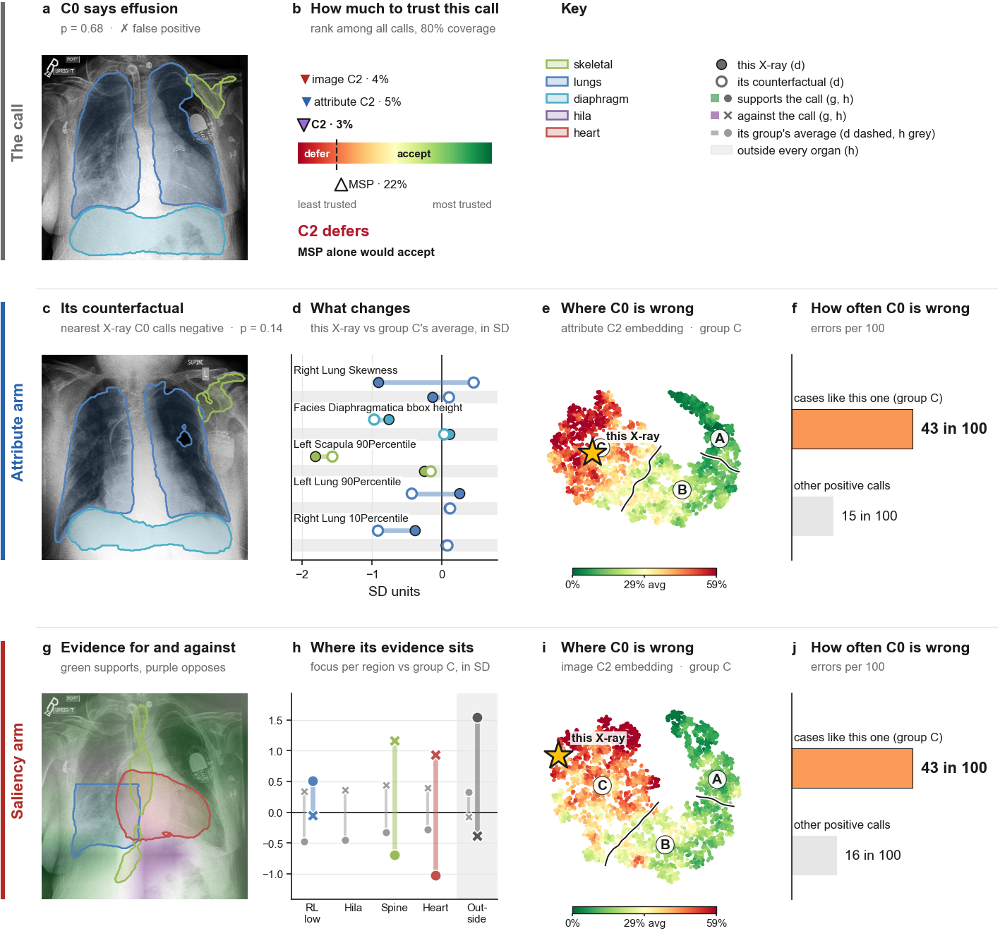

In [ ]:
combined_card(pick_combined_cos(1, "wrong", verdict="defer", msp="disagree", arms="agree",
                                margin=0.005, held_out="any", group_attr="C", group_img="C", nth=3))
